In [1]:
# 第 1 步：检查运行环境，固定随机种子
import sys
import random
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Random seed:", SEED)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU")

x = torch.ones(2, 3, device=device)
w = torch.ones(3, 4, device=device)
y = x @ w
assert y.shape == (2, 4)
assert torch.allclose(y, torch.full_like(y, 3.0))
print("Tensor check passed:", tuple(y.shape))

# 重启后全部运行的核对标记
from datetime import datetime, timezone
import os
RUN_STARTED_UTC = datetime.now(timezone.utc).isoformat()
RUN_PROCESS_ID = os.getpid()
print('Fresh run started:', RUN_STARTED_UTC, '| process:', RUN_PROCESS_ID)


Python: 3.13.16
PyTorch: 2.11.0+cu130
NumPy: 2.1.3
Matplotlib: 3.10.0
Random seed: 42
Device: cuda
GPU: Tesla T4
Tensor check passed: (2, 4)
Fresh run started: 2026-10-31T08:22:10.287185+00:00 | process: 20722


## 第 2 步：构造序列反转数据

固定随机种子 42，使用长度为 6 的随机数字序列（数字 0–9）。训练集 4096 条、验证集 256 条、测试集 512 条，所有原始序列互不重复。训练集用于更新参数，验证集用于检查学习过程，测试集在最终评估时使用。

**一条完整样本：**

```text
<BOS> 3 1 4 2 0 5 <SEP> 5 0 2 4 1 3 <EOS>
```

- `<BOS>` 表示开始，`<SEP>` 分隔题目与答案，`<EOS>` 表示结束。词表共 13 个 token。
- 完整样本有 15 个 token。输入 `x` 去掉最后一个 token，标签 `y` 去掉第一个 token，因此每行都是 14 个位置。
- 标签的前 7 个位置设为 `-100`，配合 `cross_entropy(ignore_index=-100)` 忽略题目部分；后 7 个位置监督 6 个反转数字和结束符。
- 第 7 个位置（从 0 开始计数）的输入是 `<SEP>`，它负责预测第一个答案数字。这时题目已经完整可见。
- 训练时可一次输入错位后的完整序列，后续使用因果 mask 阻止读取未来答案；推理时只提供 `<BOS> + 题目 + <SEP>`，由模型逐个生成答案。

本步将检查数据集无交集、答案反转正确、输入/标签错位正确，以及每条样本恰好有 7 个有效监督位置。


In [2]:
# 第 2A 步：生成互不重复的数字序列，并构造输入和标签
SEQ_LEN = 6
BOS, SEP, EOS = 10, 11, 12
VOCAB_SIZE = 13
IGNORE_INDEX = -100
PROMPT_LEN = SEQ_LEN + 2        # BOS + 6 个数字 + SEP，共 8 个 token
MAX_SEQ_LEN = 2 * SEQ_LEN + 3   # 完整样本共 15 个 token

N_TRAIN, N_VAL, N_TEST = 4096, 256, 512
data_rng = random.Random(SEED)  # 独立随机数生成器，重复运行本单元仍生成相同数据
unique_codes = data_rng.sample(range(10 ** SEQ_LEN), N_TRAIN + N_VAL + N_TEST)
# 补足 6 位以保留开头的 0，例如 000123 对应 (0, 0, 0, 1, 2, 3)
all_sequences = [tuple(int(c) for c in f"{code:0{SEQ_LEN}d}")
                 for code in unique_codes]
train_sequences = all_sequences[:N_TRAIN]
val_sequences = all_sequences[N_TRAIN:N_TRAIN + N_VAL]
test_sequences = all_sequences[N_TRAIN + N_VAL:]

def encode_sequence(sequence):
    """完整序列：BOS、题目、SEP、反转答案、EOS。"""
    digits = list(sequence)
    return [BOS] + digits + [SEP] + digits[::-1] + [EOS]

def make_xy(sequences):
    """每个输入位置预测下一个 token，只监督答案和 EOS。"""
    full = torch.tensor([encode_sequence(s) for s in sequences], dtype=torch.long)
    inputs = full[:, :-1].contiguous()
    labels = full[:, 1:].clone()
    labels[:, :PROMPT_LEN - 1] = IGNORE_INDEX
    return inputs, labels

def token_name(token):
    return {BOS: "<BOS>", SEP: "<SEP>", EOS: "<EOS>",
            IGNORE_INDEX: "IGNORE"}.get(int(token), str(int(token)))

def decode_tokens(tokens):
    return " ".join(token_name(t) for t in tokens)

train_x, train_y = make_xy(train_sequences)
val_x, val_y = make_xy(val_sequences)
test_x, test_y = make_xy(test_sequences)
raw_splits = {"train": train_sequences, "validation": val_sequences,
              "test": test_sequences}
data_splits = {"train": (train_x, train_y), "validation": (val_x, val_y),
               "test": (test_x, test_y)}

print("Vocabulary:", VOCAB_SIZE, "tokens; digit sequence length:", SEQ_LEN)
for name, (inputs, labels) in data_splits.items():
    print(f"{name:10s}: x={tuple(inputs.shape)}, y={tuple(labels.shape)}")
print("\nExample from training set:")
print("Full:  ", decode_tokens(encode_sequence(train_sequences[0])))
print("Input: ", decode_tokens(train_x[0]))
print("Target:", decode_tokens(train_y[0]))
print("\nGeneration prompt (question only):")
print(decode_tokens(train_x[0, :PROMPT_LEN]))


Vocabulary: 13 tokens; digit sequence length: 6
train     : x=(4096, 14), y=(4096, 14)
validation: x=(256, 14), y=(256, 14)
test      : x=(512, 14), y=(512, 14)

Example from training set:
Full:   <BOS> 6 7 0 4 8 7 <SEP> 7 8 4 0 7 6 <EOS>
Input:  <BOS> 6 7 0 4 8 7 <SEP> 7 8 4 0 7 6
Target: IGNORE IGNORE IGNORE IGNORE IGNORE IGNORE IGNORE 7 8 4 0 7 6 <EOS>

Generation prompt (question only):
<BOS> 6 7 0 4 8 7 <SEP>


In [3]:
# 第 2B 步：检查所有样本，并打印逐位置的监督关系
train_set = set(train_sequences)
val_set = set(val_sequences)
test_set = set(test_sequences)
assert len(train_set) == N_TRAIN
assert len(val_set) == N_VAL
assert len(test_set) == N_TEST
assert train_set.isdisjoint(val_set)
assert train_set.isdisjoint(test_set)
assert val_set.isdisjoint(test_set)

for name, (inputs, labels) in data_splits.items():
    sources = torch.tensor(raw_splits[name], dtype=torch.long)
    assert inputs.dtype == labels.dtype == torch.long
    assert inputs.shape == labels.shape == (len(sources), MAX_SEQ_LEN - 1)
    assert ((sources >= 0) & (sources <= 9)).all()
    assert torch.equal(inputs[:, 1:SEQ_LEN + 1], sources)
    assert (inputs[:, 0] == BOS).all()
    assert (inputs[:, PROMPT_LEN - 1] == SEP).all()
    assert torch.equal(inputs[:, PROMPT_LEN:], sources.flip(1))
    assert (labels[:, :PROMPT_LEN - 1] == IGNORE_INDEX).all()
    assert torch.equal(labels[:, PROMPT_LEN - 1:-1], sources.flip(1))
    assert (labels[:, -1] == EOS).all()
    assert ((labels != IGNORE_INDEX).sum(1) == SEQ_LEN + 1).all()
    # 有效标签应等于输入的下一个 token，最后一个标签为 EOS
    assert torch.equal(labels[:, PROMPT_LEN - 1:-1], inputs[:, PROMPT_LEN:])

# 检查补零编码，保证开头为 0 的序列仍有 6 个数字
assert encode_sequence((0, 0, 0, 1, 2, 3)) == [BOS, 0, 0, 0, 1, 2, 3, SEP, 3, 2, 1, 0, 0, 0, EOS]

print("PASS: all 4864 sequences are unique; split overlap = 0")
print("PASS: reversal, next-token shift, token IDs, and tensor shapes")
print("PASS: each sample has 7 supervised targets (6 digits + EOS)")
print("Example batch: x =", tuple(train_x[:64].shape),
      ", y =", tuple(train_y[:64].shape))
print("\nPosition | Input   | Loss target")
print("---------|---------|------------")
for position, (input_id, target_id) in enumerate(zip(train_x[0], train_y[0])):
    print(f"{position:8d} | {token_name(input_id):7s} | {token_name(target_id)}")
print("\nData checks passed. Ready for handwritten attention.")


PASS: all 4864 sequences are unique; split overlap = 0
PASS: reversal, next-token shift, token IDs, and tensor shapes
PASS: each sample has 7 supervised targets (6 digits + EOS)
Example batch: x = (64, 14) , y = (64, 14)

Position | Input   | Loss target
---------|---------|------------
       0 | <BOS>   | IGNORE
       1 | 6       | IGNORE
       2 | 7       | IGNORE
       3 | 0       | IGNORE
       4 | 4       | IGNORE
       5 | 8       | IGNORE
       6 | 7       | IGNORE
       7 | <SEP>   | 7
       8 | 7       | 8
       9 | 8       | 4
      10 | 4       | 0
      11 | 0       | 7
      12 | 7       | 6
      13 | 6       | <EOS>

Data checks passed. Ready for handwritten attention.


## 第 3 步：手写缩放点积注意力与多头自注意力

### 3A. 一个注意力头的计算

对于同一输入表示 X，使用不同的可学习线性投影得到 Q、K、V。Q 表示当前位置的查询，K 用于匹配，V 提供汇总内容。

$$Q=XW_Q,\quad K=XW_K,\quad V=XW_V$$

$$A=\operatorname{softmax}\left(\frac{QK^T}{\sqrt{d_k}}+M\right),\quad O=AV$$

QK 的点积得到每个 query 对各个 key 的分数。除以每头维度的平方根，可减轻维度增大时点积幅度变大的影响。softmax 沿最后一维（key 位置）归一化，所以注意力矩阵每行之和为 1。

因果模式下，行 i 只能读取列 j <= i。代码用上三角布尔矩阵表示需要屏蔽的位置，并在 softmax 前把对应分数设为负无穷。对角线保留，因为当前位置需要预测下一个 token。

### 3B. 多头拆分与拼接

使用隐藏维度 D=64、头数 H=4，则每头维度为 16。

```text
输入 X                       [B, T, 64]
线性投影后的 Q/K/V           [B, T, 64]
拆头并交换维度               [B, 4, T, 16]
注意力矩阵 A                 [B, 4, T, T]
每个头的输出                 [B, 4, T, 16]
交换维度并拼头               [B, T, 64]
输出投影                     [B, T, 64]
```

四个头分别在 16 维空间里计算注意力。拼接前需要把头维度移回序列维度之后，再用输出投影混合各个头的信息。模块同时返回输出与未平均的各头注意力，供后续画热图使用。

### 3C. 验证

先使用小矩阵观察单头权重，再验证多头形状、每行归一化、未来权重为零、修改未来输入不影响前缀，以及梯度有限。最后将相同投影参数复制到 PyTorch 官方 MultiheadAttention，仅用作独立数值对照。实验模型的前向计算全部使用手写实现。

此阶段使用随机浮点向量测试注意力模块；第 4 步再用 Embedding 将数字 token 转为模型输入向量。

公式参考：[Attention Is All You Need](https://papers.neurips.cc/paper_files/paper/2017/file/3f5ee243547dee91fbd053c1c4a845aa-Paper.pdf)。


In [4]:
# 第 3A 步：从矩阵乘法、mask 和 softmax 手写注意力
import math

def scaled_dot_product_attention_manual(q, k, v, causal=True):
    """自注意力核心。q/k/v 为 [B, H, T, 每头维度]。"""
    d_k = q.size(-1)
    scores = (q @ k.transpose(-2, -1)) / math.sqrt(d_k)
    # scores: [B, H, T, T]；行是 query，列是 key
    if causal:
        # True 表示要屏蔽；上三角对应未来位置，对角线可以读取
        blocked = torch.ones(scores.shape[-2:], dtype=torch.bool,
                             device=q.device).triu(diagonal=1)
        scores = scores.masked_fill(blocked, float("-inf"))
    weights = torch.softmax(scores, dim=-1)
    output = weights @ v
    return output, weights

# 小例子：一个 batch、一个头、3 个位置
# q=k=单位矩阵，同一位置的点积分数较高
q_demo = torch.eye(3, device=device).reshape(1, 1, 3, 3)
k_demo = q_demo.clone()
v_demo = torch.tensor([[10., 0.], [0., 20.], [30., 30.]],
                      device=device).reshape(1, 1, 3, 2)
masked_demo, masked_weights_demo = scaled_dot_product_attention_manual(
    q_demo, k_demo, v_demo, causal=True)
full_demo, full_weights_demo = scaled_dot_product_attention_manual(
    q_demo, k_demo, v_demo, causal=False)
assert torch.equal(masked_demo[0, 0, 0], v_demo[0, 0, 0])

np.set_printoptions(precision=3, suppress=True)
print("Causal attention (rows=query, columns=key):")
print(masked_weights_demo[0, 0].detach().cpu().numpy())
print("\nAttention without causal mask:")
print(full_weights_demo[0, 0].detach().cpu().numpy())
print("\nCausal output = weights @ V:")
print(masked_demo[0, 0].detach().cpu().numpy())
print("\nFirst position can only read itself: output = [10, 0]")


Causal attention (rows=query, columns=key):
[[1.    0.    0.   ]
 [0.36  0.64  0.   ]
 [0.264 0.264 0.471]]

Attention without causal mask:
[[0.471 0.264 0.264]
 [0.264 0.471 0.264]
 [0.264 0.264 0.471]]

Causal output = weights @ V:
[[10.     0.   ]
 [ 3.595 12.809]
 [16.777 19.422]]

First position can only read itself: output = [10, 0]


In [5]:
# 第 3B 步：手写多头自注意力，支持因果/无因果两种模式
class ManualMultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model=64, num_heads=4, causal=True):
        super().__init__()
        if d_model <= 0 or num_heads <= 0 or d_model % num_heads != 0:
            raise ValueError("d_model must be positive and divisible by num_heads")
        self.d_model = d_model
        self.num_heads = num_heads
        self.head_dim = d_model // num_heads
        self.causal = causal
        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)
        self.out_proj = nn.Linear(d_model, d_model)

    def _split_heads(self, tensor):
        batch_size, seq_len, _ = tensor.shape
        # [B,T,D] -> [B,T,H,Dh] -> [B,H,T,Dh]
        return tensor.reshape(batch_size, seq_len, self.num_heads,
                              self.head_dim).transpose(1, 2)

    def forward(self, x, causal=None):
        batch_size, seq_len, _ = x.shape
        use_causal = self.causal if causal is None else causal
        q = self._split_heads(self.q_proj(x))
        k = self._split_heads(self.k_proj(x))
        v = self._split_heads(self.v_proj(x))
        head_outputs, weights = scaled_dot_product_attention_manual(
            q, k, v, causal=use_causal)
        # 先交换维度，再拼接各个头；contiguous 使内存布局适合 view
        merged = head_outputs.transpose(1, 2).contiguous().view(
            batch_size, seq_len, self.d_model)
        output = self.out_proj(merged)
        # 返回每个头的权重 [B,H,T,T]，保留层/头可视化所需的信息
        return output, weights

# 当前先用随机向量验证；Embedding 将在下一步加入完整模型
torch.manual_seed(SEED)
attention_demo = ManualMultiHeadSelfAttention(64, 4, causal=True).to(device)
embedding_demo = torch.randn(2, train_x.size(1), 64, device=device)
with torch.no_grad():
    output_demo, attention_weights_demo = attention_demo(embedding_demo)
    q_shape_demo = attention_demo._split_heads(
        attention_demo.q_proj(embedding_demo)).shape

print("Input X:       ", tuple(embedding_demo.shape))
print("Q/K/V per head:", tuple(q_shape_demo))
print("Attention A:   ", tuple(attention_weights_demo.shape))
print("Final output:  ", tuple(output_demo.shape))
print("Head dimension:", attention_demo.head_dim)
print("Parameters:    ", sum(p.numel() for p in attention_demo.parameters()))


Input X:        (2, 14, 64)
Q/K/V per head: (2, 4, 14, 16)
Attention A:    (2, 4, 14, 14)
Final output:   (2, 14, 64)
Head dimension: 16
Parameters:     16640


In [6]:
# 第 3C 步：验证形状、归一化、因果性、梯度与官方数值对照
# nn.MultiheadAttention 仅在本测试函数中作为参考；实验模型使用手写类
def check_attention_implementation():
    torch.manual_seed(SEED)
    sample = torch.randn(2, train_x.size(1), 64, device=device)
    seq_len = sample.size(1)
    blocked = torch.ones(seq_len, seq_len, dtype=torch.bool,
                         device=device).triu(1)
    results = {}

    for heads in (4, 1):
        manual = ManualMultiHeadSelfAttention(64, heads).to(device).eval()
        reference = nn.MultiheadAttention(64, heads, dropout=0.0,
                                          batch_first=True).to(device).eval()
        with torch.no_grad():
            reference.in_proj_weight.copy_(torch.cat([
                manual.q_proj.weight, manual.k_proj.weight, manual.v_proj.weight]))
            reference.in_proj_bias.copy_(torch.cat([
                manual.q_proj.bias, manual.k_proj.bias, manual.v_proj.bias]))
            reference.out_proj.load_state_dict(manual.out_proj.state_dict())

            for use_causal in (True, False):
                actual, weights = manual(sample, causal=use_causal)
                expected, expected_weights = reference(
                    sample, sample, sample,
                    attn_mask=blocked if use_causal else None,
                    need_weights=True, average_attn_weights=False)
                assert actual.shape == sample.shape
                assert weights.shape == (2, heads, seq_len, seq_len)
                assert torch.isfinite(actual).all() and torch.isfinite(weights).all()
                assert (weights >= 0).all()
                assert torch.allclose(weights.sum(-1),
                                      torch.ones_like(weights.sum(-1)), atol=1e-6)
                if use_causal:
                    assert torch.count_nonzero(weights[..., blocked]).item() == 0
                assert torch.allclose(actual, expected, atol=1e-5, rtol=1e-4)
                assert torch.allclose(weights, expected_weights, atol=1e-5, rtol=1e-4)
                error = (actual - expected).abs().max().item()
                results[f"heads={heads}, causal={use_causal}"] = error
                print(f"PASS: heads={heads}, causal={use_causal}; reference max error={error:.2e}")

        if heads == 4:
            # 修改答案输入部分，保持题目和 SEP 完全相同
            changed = sample.clone()
            changed[:, PROMPT_LEN:] += 5 * torch.randn_like(changed[:, PROMPT_LEN:])
            with torch.no_grad():
                old_causal, _ = manual(sample, causal=True)
                new_causal, _ = manual(changed, causal=True)
                old_full, _ = manual(sample, causal=False)
                new_full, _ = manual(changed, causal=False)
                prefix_error = (old_causal[:, :PROMPT_LEN] -
                                new_causal[:, :PROMPT_LEN]).abs().max().item()
                full_difference = (old_full[:, :PROMPT_LEN] -
                                   new_full[:, :PROMPT_LEN]).abs().max().item()
            assert prefix_error < 1e-6
            assert full_difference > 1e-5
            results["causal_prefix_error"] = prefix_error
            results["unmasked_prefix_difference"] = full_difference
            print(f"PASS: future perturbation; causal prefix change={prefix_error:.2e}")
            print(f"CHECK: same perturbation without mask changes prefix by {full_difference:.2e}")

            gradient_input = sample.detach().clone().requires_grad_(True)
            gradient_output, _ = manual(gradient_input, causal=True)
            gradient_output.square().mean().backward()
            assert gradient_input.grad is not None
            assert torch.isfinite(gradient_input.grad).all()
            assert all(p.grad is not None and torch.isfinite(p.grad).all()
                       for p in manual.parameters())
            print("PASS: backward propagation; input and all parameter gradients are finite")

    try:
        ManualMultiHeadSelfAttention(64, 3)
    except ValueError:
        print("PASS: invalid head count is rejected (64 cannot be divided by 3)")
    else:
        raise AssertionError("Invalid head count was accepted")
    print("\nALL ATTENTION CHECKS PASSED. Ready for the Transformer Block.")
    return results

attention_check_results = check_attention_implementation()


PASS: heads=4, causal=True; reference max error=2.38e-07
PASS: heads=4, causal=False; reference max error=8.94e-08
PASS: future perturbation; causal prefix change=0.00e+00
CHECK: same perturbation without mask changes prefix by 2.35e+00
PASS: backward propagation; input and all parameter gradients are finite
PASS: heads=1, causal=True; reference max error=2.38e-07
PASS: heads=1, causal=False; reference max error=1.19e-07
PASS: invalid head count is rejected (64 cannot be divided by 3)

ALL ATTENTION CHECKS PASSED. Ready for the Transformer Block.


## 第 4 步：搭建完整的 decoder-only Transformer

### 从数字 ID 到预测分数

```text
输入 token ID                       [B, T]
Token Embedding + Position Embedding [B, T, 64]
Transformer Block 1                 [B, T, 64]
Transformer Block 2                 [B, T, 64]
Final LayerNorm                     [B, T, 64]
输出线性层（13 个 token 的分数）      [B, T, 13]
```

Token Embedding 为 13 个 token 各学习一个 64 维向量。Position Embedding 为各个位置学习一个 64 维向量，与 token 向量相加，让模型区分位置。本实验的位置编码是可学习的。

### Pre-LayerNorm Block

每个 Block 先对当前输入的最后一维（64 个特征）归一化，再计算子层输出，并加回原输入：

$$U=X+\operatorname{Attention}(\operatorname{LN}_1(X))$$
$$Y=U+\operatorname{FFN}(\operatorname{LN}_2(U))$$

- 手写多头注意力在不同位置之间汇总信息，默认启用因果 mask。
- 残差连接保留原输入，并为梯度提供直接传播路径。
- LayerNorm 在每个位置内部归一化，不会读取未来 token。
- 前馈网络对每个位置独立使用同一组参数，结构为 `Linear(64,128) -> GELU -> Linear(128,64)`。
- 使用 2 个独立 Block，每层 4 个头，dropout=0。

输出层产生 logits，即每个位置对 13 个候选 token 的未归一化分数。训练时直接把 logits 传给交叉熵，交叉熵内部处理归一化。将 logits 展平为 `[B*T,13]`，标签展平为 `[B*T]`，并设置 `ignore_index=-100`。

### 模型接口与本步验证

`model(token_ids, return_attention=False, causal=None)` 返回 `(logits, attention_maps)`。需要热图时设 `return_attention=True`，得到按层排列的列表，每层形状为 `[B,H,T,T]`。`causal` 可临时覆盖所有层的 mask，后续用于同一模型的机制对比。

本步使用独立的测试模型执行一次 Adam 更新，检查输出形状、loss、梯度、参数变化、完整模型的因果性，以及只输入题目时能否前向计算。测试结束后重新创建固定种子的正式模型，供第 5 步从头训练。一次更新只验证训练流程，学习效果将在下一步评估。


In [7]:
# 第 4A 步：Pre-LN Block 与完整的 decoder-only Transformer
class TransformerBlock(nn.Module):
    def __init__(self, d_model=64, num_heads=4, d_ff=128,
                 dropout=0.0, causal=True):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model)
        self.attention = ManualMultiHeadSelfAttention(
            d_model=d_model, num_heads=num_heads, causal=causal)
        self.norm2 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Linear(d_ff, d_model),
        )
        self.residual_dropout = nn.Dropout(dropout)

    def forward(self, x, causal=None):
        attention_output, weights = self.attention(self.norm1(x), causal=causal)
        x = x + self.residual_dropout(attention_output)
        x = x + self.residual_dropout(self.ffn(self.norm2(x)))
        return x, weights


class ToyTransformer(nn.Module):
    def __init__(self, vocab_size=13, max_seq_len=15, d_model=64,
                 num_heads=4, num_layers=2, d_ff=128, dropout=0.0, causal=True):
        super().__init__()
        self.config = dict(vocab_size=vocab_size, max_seq_len=max_seq_len,
                           d_model=d_model, num_heads=num_heads, num_layers=num_layers,
                           d_ff=d_ff, dropout=dropout, causal=causal)
        self.max_seq_len = max_seq_len
        self.token_embedding = nn.Embedding(vocab_size, d_model)
        self.position_embedding = nn.Embedding(max_seq_len, d_model)
        # 每次构造一个新 Block，确保不同层拥有独立参数
        self.blocks = nn.ModuleList([
            TransformerBlock(d_model, num_heads, d_ff, dropout, causal)
            for _ in range(num_layers)
        ])
        self.final_norm = nn.LayerNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size)
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
        if isinstance(module, nn.Linear) and module.bias is not None:
            nn.init.zeros_(module.bias)

    def forward(self, token_ids, return_attention=False, causal=None):
        if token_ids.ndim != 2:
            raise ValueError("token_ids must have shape [batch, sequence]")
        seq_len = token_ids.size(1)
        if not 1 <= seq_len <= self.max_seq_len:
            raise ValueError(f"Sequence length must be between 1 and {self.max_seq_len}")
        positions = torch.arange(seq_len, device=token_ids.device)
        x = (self.token_embedding(token_ids)
             + self.position_embedding(positions).unsqueeze(0))
        attention_maps = []
        for block in self.blocks:
            x, weights = block(x, causal=causal)
            if return_attention:
                attention_maps.append(weights)
        logits = self.lm_head(self.final_norm(x))
        return logits, attention_maps


MODEL_CONFIG = dict(vocab_size=VOCAB_SIZE, max_seq_len=MAX_SEQ_LEN,
                    d_model=64, num_heads=4, num_layers=2, d_ff=128,
                    dropout=0.0, causal=True)

def make_model(num_heads=4, causal=True, seed=SEED):
    """基准模型和消融模型共用的构造函数，每次从固定种子初始化。"""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    config = MODEL_CONFIG.copy()
    config.update(num_heads=num_heads, causal=causal)
    return ToyTransformer(**config).to(device)

def answer_loss(logits, labels):
    """只计算反转答案及 EOS 的交叉熵。logits 不预先做 softmax。"""
    return F.cross_entropy(logits.reshape(-1, logits.size(-1)),
                           labels.reshape(-1), ignore_index=IGNORE_INDEX)


model_preview = make_model()
with torch.no_grad():
    preview_logits, preview_attention = model_preview(
        train_x[:2].to(device), return_attention=True)
print("Model config:", model_preview.config)
print("\nParameter counts:")
for name, module in model_preview.named_children():
    print(f"{name:20s} {sum(p.numel() for p in module.parameters()):6d}")
print("Total parameters:", sum(p.numel() for p in model_preview.parameters()))
print("\nToken IDs:", tuple(train_x[:2].shape))
print("Logits:   ", tuple(preview_logits.shape))
for layer, weights in enumerate(preview_attention, 1):
    print(f"Layer {layer} attention:", tuple(weights.shape))


Model config: {'vocab_size': 13, 'max_seq_len': 15, 'd_model': 64, 'num_heads': 4, 'num_layers': 2, 'd_ff': 128, 'dropout': 0.0, 'causal': True}

Parameter counts:
token_embedding         832
position_embedding      960
blocks                66944
final_norm              128
lm_head                 845
Total parameters: 69709

Token IDs: (2, 14)
Logits:    (2, 14, 13)
Layer 1 attention: (2, 4, 14, 14)
Layer 2 attention: (2, 4, 14, 14)


In [8]:
# 第 4B 步：完整模型的前向、因果性、反向传播与一次参数更新
def check_transformer_training_step():
    smoke_model = make_model()
    initial_state = {name: value.detach().clone()
                     for name, value in smoke_model.state_dict().items()}
    batch_x = train_x[:64].to(device)
    batch_y = train_y[:64].to(device)
    assert (smoke_model.blocks[0].attention.q_proj.weight.data_ptr()
            != smoke_model.blocks[1].attention.q_proj.weight.data_ptr())

    smoke_model.eval()
    with torch.no_grad():
        full_logits, attention_maps = smoke_model(batch_x, return_attention=True)
        assert full_logits.shape == (64, 14, VOCAB_SIZE)
        assert torch.isfinite(full_logits).all()
        assert len(attention_maps) == MODEL_CONFIG["num_layers"]
        blocked = torch.ones(14, 14, dtype=torch.bool, device=device).triu(1)
        for weights in attention_maps:
            assert weights.shape == (64, 4, 14, 14)
            assert torch.isfinite(weights).all()
            assert torch.count_nonzero(weights[..., blocked]).item() == 0
            assert torch.allclose(weights.sum(-1),
                                  torch.ones_like(weights.sum(-1)), atol=1e-6)

        # 只改变未来的答案输入，题目和 SEP 保持相同
        changed_x = batch_x.clone()
        changed_x[:, PROMPT_LEN:] = (changed_x[:, PROMPT_LEN:] + 1) % 10
        changed_logits, _ = smoke_model(changed_x)
        prefix_error = (full_logits[:, :PROMPT_LEN]
                        - changed_logits[:, :PROMPT_LEN]).abs().max().item()
        assert prefix_error < 1e-6

        # 推理开始时只输入题目，模型也应可以正常处理较短的前缀
        prompt_logits, _ = smoke_model(batch_x[:, :PROMPT_LEN])
        assert prompt_logits.shape == (64, PROMPT_LEN, VOCAB_SIZE)
        assert torch.allclose(prompt_logits, full_logits[:, :PROMPT_LEN],
                              atol=1e-5, rtol=1e-4)

    print("PASS: forward shapes; logits=(64,14,13), attention=2 x (64,4,14,14)")
    print("PASS: two Blocks have independent parameters; both layers obey the mask")
    print(f"PASS: full-model future perturbation; prefix change={prefix_error:.2e}")
    print("PASS: question-only prompt works and matches the full-sequence prefix")

    smoke_model.train()
    optimizer = torch.optim.Adam(smoke_model.parameters(), lr=0.003)
    optimizer.zero_grad(set_to_none=True)
    logits, _ = smoke_model(batch_x)
    loss = answer_loss(logits, batch_y)
    assert torch.isfinite(loss)
    active = batch_y != IGNORE_INDEX
    selected_loss = F.cross_entropy(logits[active], batch_y[active])
    assert torch.allclose(loss, selected_loss, atol=1e-6)
    loss_before = loss.item()

    loss.backward()
    assert all(parameter.grad is not None
               and torch.isfinite(parameter.grad).all()
               for parameter in smoke_model.parameters())
    grad_norm = torch.nn.utils.clip_grad_norm_(smoke_model.parameters(), 1.0)
    assert torch.isfinite(grad_norm)
    optimizer.step()
    parameter_change = (smoke_model.lm_head.weight.detach()
                        - initial_state["lm_head.weight"]).abs().max().item()
    assert parameter_change > 0
    smoke_model.eval()
    with torch.no_grad():
        updated_logits, _ = smoke_model(batch_x)
        loss_after = answer_loss(updated_logits, batch_y).item()
    assert math.isfinite(loss_after)
    print(f"PASS: answer-only loss; supervised targets={active.sum().item()}")
    print(f"PASS: finite gradients; norm before clipping={grad_norm.item():.4f}")
    print(f"PASS: Adam updates parameters; max head-weight change={parameter_change:.6f}")
    print(f"Same-batch loss: {loss_before:.4f} -> {loss_after:.4f} (one update only)")

    # 正式训练模型重新从固定种子初始化，所有参数都与测试前完全一致
    fresh_model = make_model()
    assert all(torch.equal(value, initial_state[name])
               for name, value in fresh_model.state_dict().items())
    assert all(p.grad is None for p in fresh_model.parameters())
    results = dict(prefix_error=prefix_error, loss_before=loss_before,
                   loss_after=loss_after, gradient_norm=grad_norm.item(),
                   max_parameter_change=parameter_change,
                   parameter_count=sum(p.numel() for p in fresh_model.parameters()))
    print("PASS: fresh training model exactly matches the initial weights")
    print("\nALL TRANSFORMER CHECKS PASSED. Ready for training in Step 5.")
    return fresh_model, results

model, model_check_results = check_transformer_training_step()


PASS: forward shapes; logits=(64,14,13), attention=2 x (64,4,14,14)
PASS: two Blocks have independent parameters; both layers obey the mask
PASS: full-model future perturbation; prefix change=0.00e+00
PASS: question-only prompt works and matches the full-sequence prefix
PASS: answer-only loss; supervised targets=448
PASS: finite gradients; norm before clipping=2.7138
PASS: Adam updates parameters; max head-weight change=0.003000
Same-batch loss: 2.5881 -> 2.3858 (one update only)
PASS: fresh training model exactly matches the initial weights

ALL TRANSFORMER CHECKS PASSED. Ready for training in Step 5.


## 第 5 步：训练、loss 曲线与自回归反转预测

### 训练设置与公平比较

使用 Adam、学习率 0.003、batch size 64、梯度裁剪 1.0。先用独立模型预热并测速 20 步，GPU 默认训练 600 步，CPU 默认 300 步；若测速预计单模型训练超过 7 分钟，则统一下调步数。测速模型随后丢弃，正式训练重新从种子 42 初始化。验证和保存需要额外少量时间。

训练前锁定步数和每步的样本索引，后续消融复用相同配置、相同数据和相同抽样顺序。每隔约 1/12 的训练进度，在 eval 模式下计算完整训练集与验证集的答案区间交叉熵，绘制可比较的两条曲线。验证集不用于反向传播。使用固定步数后的最终模型进行评估。

### 两种检查方式

1. 教师强制 loss：输入含已知答案前缀的错位序列，因果 mask 阻止查看未来答案；只统计反转数字与 EOS。
2. 自回归生成：只输入 `<BOS> + 六个原始数字 + <SEP>`，每次取最后位置分数最高的 token，追加到输入，再预测下一个 token。生成时不提供标准答案，不限制候选 token，也不强制正确的结束位置。最多生成 7 个 token；遇到 EOS 后该条样本视为结束，缺失的答案位置计错。

测试集 Token 准确率仅统计 6 个数字；整序列准确率要求 6 个数字全部正确，且第 7 个生成 token 为首次 EOS。测试集用于最终评估，不据此修改训练超参数。

### 保存结果

结果保存在 `/content/experiment1_outputs`，包含训练配置、固定抽样索引、数据副本、训练记录、模型权重、loss 曲线、测试预测与指标。每次记录验证 loss 时更新训练检查点，完成后下载阶段备份。Colab 的运行目录属于临时环境，notebook 保存与文件下载分别执行。


In [9]:
# 第 5A 步：测速、锁定训练预算，并准备可复用的评估函数
import time
import json
import csv
from pathlib import Path

OUTPUT_DIR = Path("/content/experiment1_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BATCH_SIZE = 64
LEARNING_RATE = 0.003
CLIP_NORM = 1.0
if device.type == "cpu":
    torch.set_num_threads(min(2, torch.get_num_threads()))

def sync_device():
    if device.type == "cuda":
        torch.cuda.synchronize()

def benchmark_training_step():
    probe = make_model()
    probe.train()
    optimizer = torch.optim.Adam(probe.parameters(), lr=LEARNING_RATE)
    bx, by = train_x[:BATCH_SIZE].to(device), train_y[:BATCH_SIZE].to(device)
    def one_step():
        optimizer.zero_grad(set_to_none=True)
        logits, _ = probe(bx)
        loss = answer_loss(logits, by)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(probe.parameters(), CLIP_NORM)
        optimizer.step()
    for _ in range(3):
        one_step()
    sync_device()
    started = time.perf_counter()
    for _ in range(20):
        one_step()
    sync_device()
    return (time.perf_counter() - started) / 20

@torch.no_grad()
def teacher_forced_loss(current_model, inputs, labels, batch_size=256):
    was_training = current_model.training
    current_model.eval()
    total_loss, total_targets = 0.0, 0
    for start in range(0, len(inputs), batch_size):
        bx = inputs[start:start + batch_size].to(device)
        by = labels[start:start + batch_size].to(device)
        logits, _ = current_model(bx)
        summed_loss = F.cross_entropy(
            logits.reshape(-1, VOCAB_SIZE), by.reshape(-1),
            ignore_index=IGNORE_INDEX, reduction="sum")
        total_loss += summed_loss.item()
        total_targets += (by != IGNORE_INDEX).sum().item()
    current_model.train(was_training)
    return total_loss / total_targets

seconds_per_step = benchmark_training_step()
default_steps = 600 if device.type == "cuda" else 300
TRAIN_STEPS = max(1, min(default_steps, int(420 / max(seconds_per_step, 1e-6))))
EVAL_EVERY = max(1, TRAIN_STEPS // 12)
schedule_generator = torch.Generator().manual_seed(SEED + 100)
batch_schedule = torch.randint(N_TRAIN, (TRAIN_STEPS, BATCH_SIZE),
                               generator=schedule_generator)
TRAIN_CONFIG = dict(seed=SEED, sampling_seed=SEED + 100, batch_size=BATCH_SIZE,
                    learning_rate=LEARNING_RATE, clip_norm=CLIP_NORM,
                    steps=TRAIN_STEPS, eval_every=EVAL_EVERY,
                    benchmark_seconds_per_step=seconds_per_step,
                    device=str(device), selection="final fixed-step model")
(OUTPUT_DIR / "training_config.json").write_text(
    json.dumps(TRAIN_CONFIG, indent=2, ensure_ascii=False), encoding="utf-8")
np.savez_compressed(OUTPUT_DIR / "data_and_schedule.npz",
                    train=np.array(train_sequences), validation=np.array(val_sequences),
                    test=np.array(test_sequences), batch_schedule=batch_schedule.numpy())
print(f"Device: {device}; measured training step: {seconds_per_step:.4f} seconds")
print(f"Locked training budget: {TRAIN_STEPS} steps per model")
print(f"Estimated training updates: {TRAIN_STEPS * seconds_per_step:.1f} seconds per model")
print(f"Full train/validation loss every {EVAL_EVERY} steps")
print("Sampling schedule saved:", tuple(batch_schedule.shape))
print("Benchmark model discarded; baseline will start from seed 42.")


Device: cuda; measured training step: 0.0115 seconds
Locked training budget: 600 steps per model
Estimated training updates: 6.9 seconds per model
Full train/validation loss every 50 steps
Sampling schedule saved: (600, 64)
Benchmark model discarded; baseline will start from seed 42.


In [10]:
# 第 5B 步：固定步数训练、记录 train/validation loss，并保存检查点
def train_model(current_model, experiment_name):
    optimizer = torch.optim.Adam(current_model.parameters(), lr=LEARNING_RATE)
    train_inputs = train_x.to(device)
    train_labels = train_y.to(device)
    history, batch_losses = [], []
    sync_device()
    started = time.perf_counter()

    def record(step):
        train_loss = teacher_forced_loss(current_model, train_x, train_y)
        val_loss = teacher_forced_loss(current_model, val_x, val_y)
        if not (math.isfinite(train_loss) and math.isfinite(val_loss)):
            raise RuntimeError("Non-finite evaluation loss")
        row = dict(step=step, train_loss=train_loss, val_loss=val_loss)
        history.append(row)
        checkpoint = dict(
            model_state={k: v.detach().cpu() for k, v in current_model.state_dict().items()},
            optimizer_state=optimizer.state_dict(),
            model_config=current_model.config, training_config=TRAIN_CONFIG,
            step=step, history=history, batch_losses=batch_losses,
            elapsed_seconds=time.perf_counter() - started)
        torch.save(checkpoint, OUTPUT_DIR / f"{experiment_name}_latest.pt")
        (OUTPUT_DIR / f"{experiment_name}_history.json").write_text(
            json.dumps(history, indent=2), encoding="utf-8")
        print(f"{experiment_name}: step {step:3d}/{TRAIN_STEPS} | "
              f"train loss {train_loss:.6f} | val loss {val_loss:.6f}", flush=True)

    record(0)
    current_model.train()
    for step, indices_cpu in enumerate(batch_schedule, start=1):
        indices = indices_cpu.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits, _ = current_model(train_inputs[indices])
        loss = answer_loss(logits, train_labels[indices])
        if not torch.isfinite(loss).item():
            raise RuntimeError(f"Non-finite loss at step {step}")
        loss.backward()
        torch.nn.utils.clip_grad_norm_(current_model.parameters(), CLIP_NORM,
                                       error_if_nonfinite=True)
        optimizer.step()
        batch_losses.append(loss.item())
        if step % EVAL_EVERY == 0 or step == TRAIN_STEPS:
            record(step)

    sync_device()
    training_seconds = time.perf_counter() - started
    current_model.eval()
    torch.save(dict(
        model_state={k: v.detach().cpu() for k, v in current_model.state_dict().items()},
        model_config=current_model.config, training_config=TRAIN_CONFIG,
        training_seconds=training_seconds, steps=TRAIN_STEPS),
        OUTPUT_DIR / f"{experiment_name}_final.pt")
    with (OUTPUT_DIR / f"{experiment_name}_history.csv").open(
            "w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(file, fieldnames=["step", "train_loss", "val_loss"])
        writer.writeheader()
        writer.writerows(history)
    (OUTPUT_DIR / f"{experiment_name}_batch_losses.json").write_text(
        json.dumps(batch_losses), encoding="utf-8")
    print(f"Finished {experiment_name}: {training_seconds:.2f} seconds including evaluation/checkpoints")
    return history, batch_losses, training_seconds

# 从固定种子重新初始化，排除测速和第 4 步测试的参数更新
model = make_model(num_heads=4, causal=True)
baseline_history, baseline_batch_losses, baseline_training_seconds = train_model(
    model, "baseline")


baseline: step   0/600 | train loss 2.592788 | val loss 2.596880
baseline: step  50/600 | train loss 0.011877 | val loss 0.011922
baseline: step 100/600 | train loss 0.003019 | val loss 0.003023
baseline: step 150/600 | train loss 0.001896 | val loss 0.001898
baseline: step 200/600 | train loss 0.001309 | val loss 0.001310
baseline: step 250/600 | train loss 0.000959 | val loss 0.000959
baseline: step 300/600 | train loss 0.000734 | val loss 0.000735
baseline: step 350/600 | train loss 0.000581 | val loss 0.000582
baseline: step 400/600 | train loss 0.000472 | val loss 0.000473
baseline: step 450/600 | train loss 0.000392 | val loss 0.000392
baseline: step 500/600 | train loss 0.000331 | val loss 0.000331
baseline: step 550/600 | train loss 0.000283 | val loss 0.000283
baseline: step 600/600 | train loss 0.000245 | val loss 0.000245
Finished baseline: 11.02 seconds including evaluation/checkpoints


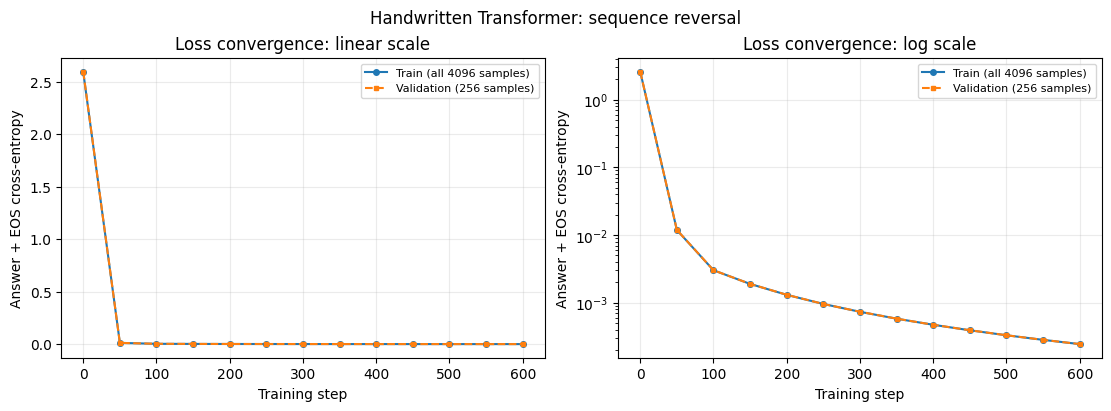

Train loss: 2.592788 -> 0.000245
Validation loss: 2.596880 -> 0.000245
Saved baseline_loss.png and baseline_loss.pdf


In [11]:
# 第 5C 步：绘制完整训练集与验证集的 loss 曲线
steps = [row["step"] for row in baseline_history]
train_curve = [row["train_loss"] for row in baseline_history]
val_curve = [row["val_loss"] for row in baseline_history]
assert len(steps) == len(train_curve) == len(val_curve)
assert steps[-1] == TRAIN_STEPS
assert all(math.isfinite(value) and value > 0
           for value in train_curve + val_curve)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax in axes:
    ax.plot(steps, train_curve, "o-", markersize=4, label="Train (all 4096 samples)")
    ax.plot(steps, val_curve, "s--", markersize=3, label="Validation (256 samples)")
    ax.set_xlabel("Training step")
    ax.set_ylabel("Answer + EOS cross-entropy")
    ax.grid(True, alpha=0.25)
    ax.legend(fontsize=8)
axes[0].set_title("Loss convergence: linear scale")
axes[1].set_title("Loss convergence: log scale")
axes[1].set_yscale("log")
fig.suptitle("Handwritten Transformer: sequence reversal")
fig.savefig(OUTPUT_DIR / "baseline_loss.png", dpi=180, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "baseline_loss.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Train loss: {train_curve[0]:.6f} -> {train_curve[-1]:.6f}")
print(f"Validation loss: {val_curve[0]:.6f} -> {val_curve[-1]:.6f}")
print("Saved baseline_loss.png and baseline_loss.pdf")


In [12]:
# 第 5D 步：只输入题目，自回归生成；评估全部 512 条独立测试样本
@torch.no_grad()
def generate_answers(current_model, prompts):
    was_training = current_model.training
    current_model.eval()
    tokens = prompts.to(device).clone()
    assert tokens.size(1) == PROMPT_LEN
    assert (tokens[:, -1] == SEP).all()
    finished = torch.zeros(tokens.size(0), dtype=torch.bool, device=device)
    generated = []
    for _ in range(SEQ_LEN + 1):
        logits, _ = current_model(tokens)
        next_token = logits[:, -1].argmax(dim=-1)
        # 已结束的样本保持 EOS，使缺失数字在评估中计错
        next_token = torch.where(finished, torch.full_like(next_token, EOS), next_token)
        generated.append(next_token)
        finished = finished | (next_token == EOS)
        tokens = torch.cat([tokens, next_token.unsqueeze(1)], dim=1)
    current_model.train(was_training)
    return torch.stack(generated, dim=1).cpu()

def format_generation(tokens):
    values = [int(t) for t in tokens]
    if EOS in values:
        return decode_tokens(values[:values.index(EOS) + 1])
    return decode_tokens(values) + " [NO EOS]"

def evaluate_model(current_model, experiment_name, training_seconds):
    sources = torch.tensor(test_sequences, dtype=torch.long)
    # prompts 从原始题目构造，完全不包含反转答案
    prompts = torch.cat([torch.full((len(sources), 1), BOS), sources,
                         torch.full((len(sources), 1), SEP)], dim=1)
    started = time.perf_counter()
    predictions = torch.cat([generate_answers(current_model, prompts[start:start + 128])
                             for start in range(0, len(prompts), 128)], dim=0)
    generation_seconds = time.perf_counter() - started
    assert predictions.shape == (N_TEST, SEQ_LEN + 1)
    expected = sources.flip(1)
    digit_matches = predictions[:, :SEQ_LEN] == expected
    eos_correct = ((predictions[:, :SEQ_LEN] != EOS).all(dim=1)
                   & (predictions[:, SEQ_LEN] == EOS))
    exact_matches = digit_matches.all(dim=1) & eos_correct
    metrics = dict(
        experiment=experiment_name, seed=SEED,
        num_heads=current_model.config["num_heads"],
        causal=current_model.config["causal"],
        parameters=sum(p.numel() for p in current_model.parameters()),
        training_steps=TRAIN_STEPS, training_seconds=training_seconds,
        test_samples=N_TEST, test_digit_tokens=N_TEST * SEQ_LEN,
        test_teacher_forced_loss=teacher_forced_loss(current_model, test_x, test_y),
        correct_digit_tokens=int(digit_matches.sum().item()),
        token_accuracy=digit_matches.float().mean().item(),
        exact_sequences=int(exact_matches.sum().item()),
        sequence_accuracy=exact_matches.float().mean().item(),
        eos_position_accuracy=eos_correct.float().mean().item(),
        generation_seconds=generation_seconds)
    rows = [dict(sample_id=i, source=decode_tokens(sources[i]),
                 expected=decode_tokens(expected[i]) + " <EOS>",
                 generated=format_generation(predictions[i]),
                 exact_match=bool(exact_matches[i].item())) for i in range(N_TEST)]
    (OUTPUT_DIR / f"{experiment_name}_metrics.json").write_text(
        json.dumps(metrics, indent=2, ensure_ascii=False), encoding="utf-8")
    with (OUTPUT_DIR / f"{experiment_name}_predictions.csv").open(
            "w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(file, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
    np.savez_compressed(OUTPUT_DIR / f"{experiment_name}_predictions.npz",
                        source=sources.numpy(), generated=predictions.numpy(),
                        expected=expected.numpy(), exact_match=exact_matches.numpy())
    print(f"{experiment_name}: independent test set, greedy autoregressive generation")
    print(f"Token accuracy (6 digits): {metrics['token_accuracy']:.2%} "
          f"({metrics['correct_digit_tokens']}/{metrics['test_digit_tokens']})")
    print(f"Sequence accuracy (6 digits + correct EOS): {metrics['sequence_accuracy']:.2%} "
          f"({metrics['exact_sequences']}/{N_TEST})")
    print(f"EOS at expected position: {metrics['eos_position_accuracy']:.2%}")
    print(f"Test teacher-forced loss: {metrics['test_teacher_forced_loss']:.6f}")
    print("\nFirst 5 test samples (fixed order):")
    for row in rows[:5]:
        print(f"#{row['sample_id']} source:    {row['source']}")
        print(f"   expected: {row['expected']}")
        print(f"   generated:{row['generated']} | exact={row['exact_match']}")
    errors = [row for row in rows if not row["exact_match"]]
    print(f"\nErrors in all {N_TEST} test samples: {len(errors)}")
    for row in errors[:3]:
        print("Error example:", row)
    return metrics, predictions, rows

baseline_model = model
baseline_metrics, baseline_predictions, baseline_prediction_rows = evaluate_model(
    baseline_model, "baseline", baseline_training_seconds)
experiment_results = {"baseline": baseline_metrics}


baseline: independent test set, greedy autoregressive generation
Token accuracy (6 digits): 100.00% (3072/3072)
Sequence accuracy (6 digits + correct EOS): 100.00% (512/512)
EOS at expected position: 100.00%
Test teacher-forced loss: 0.000245

First 5 test samples (fixed order):
#0 source:    0 2 8 2 2 3
   expected: 3 2 2 8 2 0 <EOS>
   generated:3 2 2 8 2 0 <EOS> | exact=True
#1 source:    9 9 9 2 9 7
   expected: 7 9 2 9 9 9 <EOS>
   generated:7 9 2 9 9 9 <EOS> | exact=True
#2 source:    7 6 2 5 3 8
   expected: 8 3 5 2 6 7 <EOS>
   generated:8 3 5 2 6 7 <EOS> | exact=True
#3 source:    4 8 4 0 4 5
   expected: 5 4 0 4 8 4 <EOS>
   generated:5 4 0 4 8 4 <EOS> | exact=True
#4 source:    9 8 8 7 8 0
   expected: 0 8 7 8 8 9 <EOS>
   generated:0 8 7 8 8 9 <EOS> | exact=True

Errors in all 512 test samples: 0


In [13]:
# 第 5E 步：验证保存的权重、记录环境并下载阶段备份
import hashlib
import zipfile
from google.colab import files

saved = torch.load(OUTPUT_DIR / "baseline_final.pt", map_location=device, weights_only=True)
restored_model = ToyTransformer(**saved["model_config"]).to(device)
restored_model.load_state_dict(saved["model_state"])
restored_model.eval()
restored_predictions = generate_answers(restored_model, test_x[:32, :PROMPT_LEN])
assert torch.equal(restored_predictions, baseline_predictions[:32])
print("PASS: reloaded saved weights reproduce all 32 checked generations")

environment = dict(python=sys.version, pytorch=str(torch.__version__),
                   numpy=np.__version__, matplotlib=matplotlib.__version__,
                   device=str(device),
                   gpu=torch.cuda.get_device_name(0) if device.type == "cuda" else None)
(OUTPUT_DIR / "environment.json").write_text(
    json.dumps(environment, indent=2, ensure_ascii=False), encoding="utf-8")
summary = (
    "实验一：第 5 步阶段结果\n"
    f"固定长度：{SEQ_LEN}；训练步数：{TRAIN_STEPS}；种子：{SEED}\n"
    f"训练耗时（含验证及保存）：{baseline_training_seconds:.3f} 秒\n"
    f"训练 loss：{baseline_history[0]['train_loss']:.6f} -> {baseline_history[-1]['train_loss']:.6f}\n"
    f"验证 loss：{baseline_history[0]['val_loss']:.6f} -> {baseline_history[-1]['val_loss']:.6f}\n"
    f"测试 Token 准确率：{baseline_metrics['token_accuracy']:.2%}\n"
    f"测试整序列准确率（含正确结束）：{baseline_metrics['sequence_accuracy']:.2%}\n"
    "生成只输入题目；结论仅针对当前固定长度任务及独立测试集。\n"
    "Notebook 代码与输出另保存在 Google Drive。后续继续注意力可视化、消融和报告。\n"
)
(OUTPUT_DIR / "step5_summary.txt").write_text(summary, encoding="utf-8")
manifest = {file.name: hashlib.sha256(file.read_bytes()).hexdigest()
            for file in sorted(OUTPUT_DIR.iterdir())
            if file.is_file() and file.name != "SHA256.json"}
(OUTPUT_DIR / "SHA256.json").write_text(
    json.dumps(manifest, indent=2), encoding="utf-8")
BACKUP_PATH = Path("/content/experiment1_step5_backup.zip")
with zipfile.ZipFile(BACKUP_PATH, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for file in sorted(OUTPUT_DIR.iterdir()):
        if file.is_file():
            archive.write(file, arcname=f"experiment1_outputs/{file.name}")
with zipfile.ZipFile(BACKUP_PATH) as archive:
    assert archive.testzip() is None
print(summary)
print(f"Backup ready: {BACKUP_PATH.name}; {BACKUP_PATH.stat().st_size / 1024:.1f} KiB")
print("Files:", ", ".join(sorted(file.name for file in OUTPUT_DIR.iterdir() if file.is_file())))
print("阶段备份保留在运行目录；最终统一打包下载。")


PASS: reloaded saved weights reproduce all 32 checked generations
实验一：第 5 步阶段结果
固定长度：6；训练步数：600；种子：42
训练耗时（含验证及保存）：11.021 秒
训练 loss：2.592788 -> 0.000245
验证 loss：2.596880 -> 0.000245
测试 Token 准确率：100.00%
测试整序列准确率（含正确结束）：100.00%
生成只输入题目；结论仅针对当前固定长度任务及独立测试集。
Notebook 代码与输出另保存在 Google Drive。后续继续注意力可视化、消融和报告。

Backup ready: experiment1_step5_backup.zip; 4399.8 KiB
Files: README.md, SHA256.json, ablation_alignment_diagnostics.json, ablation_comparison.pdf, ablation_comparison.png, ablation_controls.json, ablation_reload_checks.json, ablation_results.csv, ablation_results.json, ablation_results.md, attention_all_heads.pdf, attention_all_heads.png, attention_mask_comparison.pdf, attention_mask_comparison.png, attention_reverse_alignment.pdf, attention_reverse_alignment.png, attention_sample0.json, attention_sample0.npz, attention_statistics.csv, baseline_batch_losses.json, baseline_final.pt, baseline_history.csv, baseline_history.json, baseline_latest.pt, baseline_loss.pdf, baseline_loss.png, 

In [14]:
# 第 5F 步：阶段备份说明
print("第五步备份已生成；为避免 notebook 内嵌重复 ZIP，使用末尾的最终提交包下载链接。")

第五步备份已生成；为避免 notebook 内嵌重复 ZIP，使用末尾的最终提交包下载链接。


## 第 6 步：不同层、不同头的注意力与因果 mask 对比

### 实验条件

固定第 5 步已经训练好的基准模型，使用测试集第 0 条样本。所有可视化调用 eval() 和 no_grad()，模型权重不更新。注意力矩阵保留各层、各头，形状为 [2,4,14,14]。比较时使用完全相同的输入、权重和颜色范围。

### 热图怎样读

- 横轴为 key（被读取的位置），纵轴为 query（发起查询的位置）。标签同时显示位置编号和 token，用来区分重复数字。
- 因果 mask 下，query i 只能读取 key j <= i，所以主对角线以上的权重为 0。
- 第 7 行的输入为 SEP，它预测第一个答案数字。第 7–12 行依次预测六个反转数字，第 13 行预测 EOS。
- 反转的直接对齐参考为：query 7,8,9,10,11,12 分别读取原题位置 6,5,4,3,2,1。
- 全图展示完整注意力；局部图仅截取答案查询与原题 key，仍使用原始权重，不对局部重新归一化。红框标出直接反转对齐的参考位置。

### 两种比较及其含义

1. 在含标准答案前缀的完整错位输入上，切换所有层的 causal 参数，展示未来注意力如何出现。无 mask 模式可看到未来答案，此处只作机制演示。
2. 只给题目，让同一模型分别在有/无 mask 时自回归生成，比较真实生成指标。生成时仍不输入标准答案。

这一阶段研究同一组权重在切换 mask 后的行为。第 7 步另行从头训练无 mask 模型，研究训练条件的差异，两者分别记录。

注意力较亮只说明该头在这次输入上分配了较高权重；不同头可以分工，深层也可以读取前层已经加工的信息。红框对齐用于辅助观察，不预设每个头都应呈现同一种图案，也不单凭热图推断某个头的因果重要性。


In [15]:
# 第 6A 步：同一权重、同一输入，提取有/无因果 mask 的注意力
assert "baseline_model" in globals(), "Reconnect the previous runtime or rerun Steps 1-5 first"
baseline_model.eval()
step6_state_before = {k: v.detach().clone() for k, v in baseline_model.state_dict().items()}
VIS_SAMPLE_ID = 0
vis_input = test_x[VIS_SAMPLE_ID:VIS_SAMPLE_ID + 1].to(device)
vis_labels = test_y[VIS_SAMPLE_ID:VIS_SAMPLE_ID + 1].to(device)
with torch.no_grad():
    causal_logits, causal_maps = baseline_model(vis_input, return_attention=True, causal=True)
    unmasked_logits, unmasked_maps = baseline_model(vis_input, return_attention=True, causal=False)
    causal_sample_loss = answer_loss(causal_logits, vis_labels).item()
    unmasked_sample_loss = answer_loss(unmasked_logits, vis_labels).item()

causal_attention = torch.stack(causal_maps)[:, 0].cpu().numpy()
unmasked_attention = torch.stack(unmasked_maps)[:, 0].cpu().numpy()
num_layers, num_heads, vis_len, _ = causal_attention.shape
assert causal_attention.shape == unmasked_attention.shape == (2, 4, 14, 14)
future_positions = np.triu(np.ones((vis_len, vis_len), dtype=bool), k=1)
assert np.count_nonzero(causal_attention[:, :, future_positions]) == 0
assert unmasked_attention[:, :, future_positions].sum() > 0
for matrices in (causal_attention, unmasked_attention):
    assert np.isfinite(matrices).all() and (matrices >= 0).all()
    assert np.allclose(matrices.sum(-1), 1, atol=1e-6)

answer_queries = np.arange(PROMPT_LEN - 1, PROMPT_LEN - 1 + SEQ_LEN)
source_keys = np.arange(1, SEQ_LEN + 1)
expected_keys = source_keys[::-1]
vis_tokens = vis_input[0].cpu().tolist()
axis_labels = [f"{i}:{token_name(t).strip('<>')}" for i, t in enumerate(vis_tokens)]
expected_answer = list(test_sequences[VIS_SAMPLE_ID])[::-1]
attention_statistics = []
for mode, matrices in (("causal", causal_attention), ("unmasked", unmasked_attention)):
    for layer in range(num_layers):
        for head in range(num_heads):
            matrix = matrices[layer, head]
            row = dict(mode=mode, layer=layer + 1, head=head + 1,
                       mean_future_mass=float((matrix * future_positions).sum(-1).mean()),
                       answer_future_mass=float((matrix[answer_queries] * future_positions[answer_queries]).sum(-1).mean()),
                       answer_source_mass=float(matrix[np.ix_(answer_queries, source_keys)].sum(-1).mean()),
                       expected_source_alignment=float(matrix[answer_queries, expected_keys].mean()))
            attention_statistics.append(row)
with (OUTPUT_DIR / "attention_statistics.csv").open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=list(attention_statistics[0]))
    writer.writeheader()
    writer.writerows(attention_statistics)
np.savez_compressed(OUTPUT_DIR / "attention_sample0.npz",
                    causal=causal_attention, unmasked=unmasked_attention,
                    tokens=np.array(vis_tokens), answer_queries=answer_queries,
                    source_keys=source_keys, expected_keys=expected_keys)
vis_metadata = dict(sample_id=VIS_SAMPLE_ID, source=list(test_sequences[VIS_SAMPLE_ID]),
                    expected_answer=expected_answer, axis_labels=axis_labels,
                    causal_sample_loss=causal_sample_loss,
                    unmasked_sample_loss=unmasked_sample_loss,
                    comparison="same causal-trained weights; full teacher-forced input")
(OUTPUT_DIR / "attention_sample0.json").write_text(
    json.dumps(vis_metadata, indent=2, ensure_ascii=False), encoding="utf-8")
print("Baseline model retained in runtime; no retraining.")
print("Source:", decode_tokens(test_sequences[VIS_SAMPLE_ID]))
print("Expected:", decode_tokens(expected_answer), "<EOS>")
print("Attention shape [layers,heads,query,key]:", causal_attention.shape)
print("Query rows for the six answer digits:", answer_queries.tolist())
print("Direct reversal reference key positions:", expected_keys.tolist())
print("\nMean future mass over all query rows (causal -> unmasked):")
for layer in range(1, num_layers + 1):
    for head in range(1, num_heads + 1):
        rows = [r for r in attention_statistics if r['layer'] == layer and r['head'] == head]
        print(f"L{layer} H{head}: {rows[0]['mean_future_mass']:.2%} -> {rows[1]['mean_future_mass']:.2%}")
print(f"\nSame-sample teacher-forced loss: causal={causal_sample_loss:.6f}, unmasked={unmasked_sample_loss:.6f}")


Baseline model retained in runtime; no retraining.
Source: 0 2 8 2 2 3
Expected: 3 2 2 8 2 0 <EOS>
Attention shape [layers,heads,query,key]: (2, 4, 14, 14)
Query rows for the six answer digits: [7, 8, 9, 10, 11, 12]
Direct reversal reference key positions: [6, 5, 4, 3, 2, 1]

Mean future mass over all query rows (causal -> unmasked):
L1 H1: 0.00% -> 24.39%
L1 H2: 0.00% -> 25.74%
L1 H3: 0.00% -> 26.05%
L1 H4: 0.00% -> 25.38%
L2 H1: 0.00% -> 43.85%
L2 H2: 0.00% -> 46.62%
L2 H3: 0.00% -> 44.02%
L2 H4: 0.00% -> 44.83%

Same-sample teacher-forced loss: causal=0.000250, unmasked=0.000251


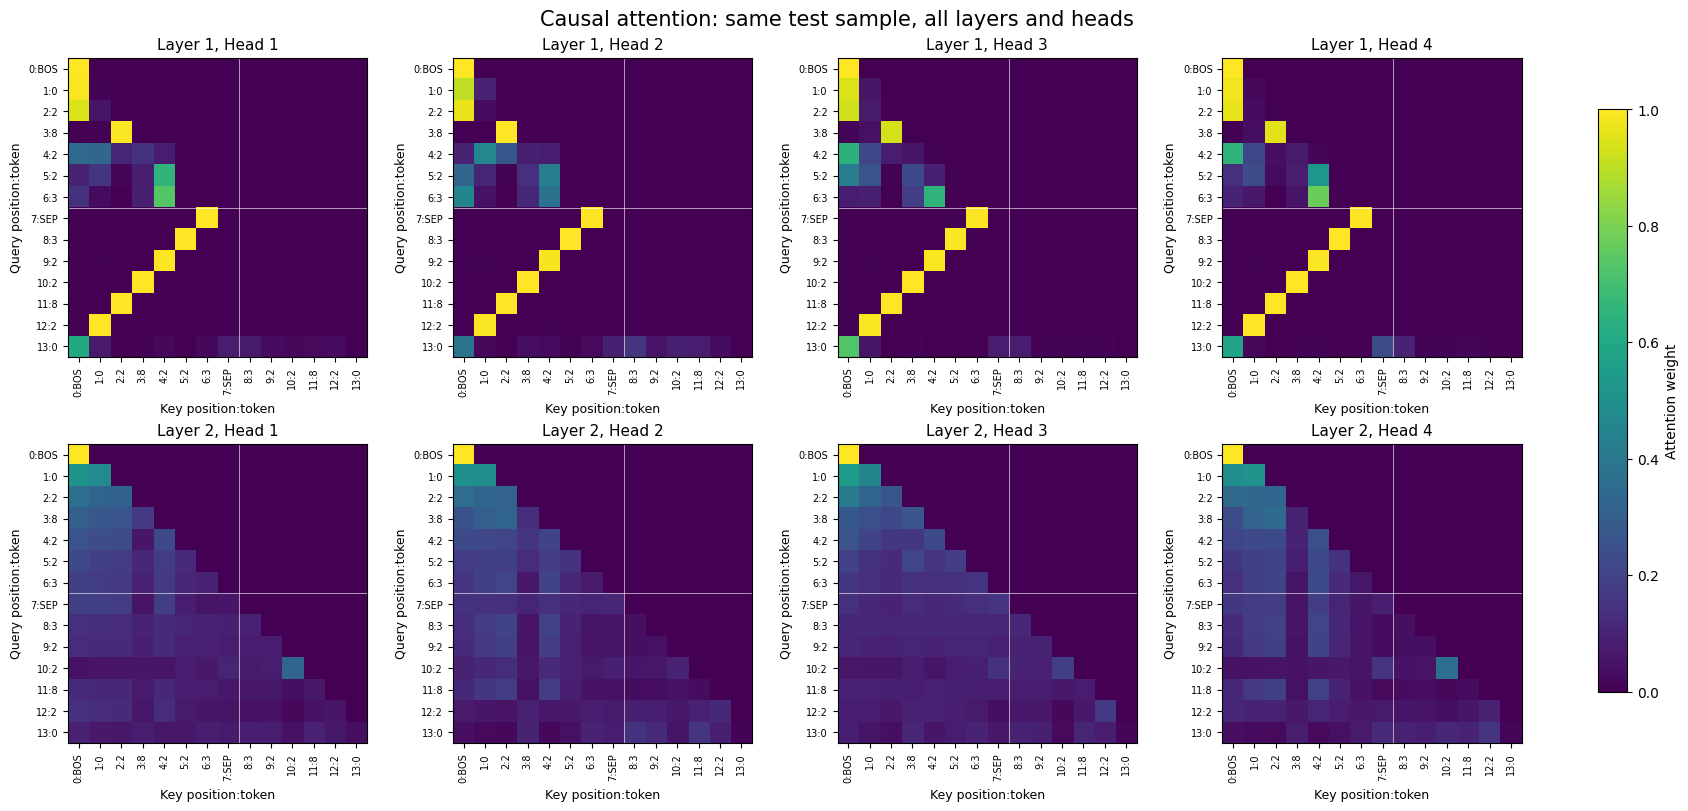

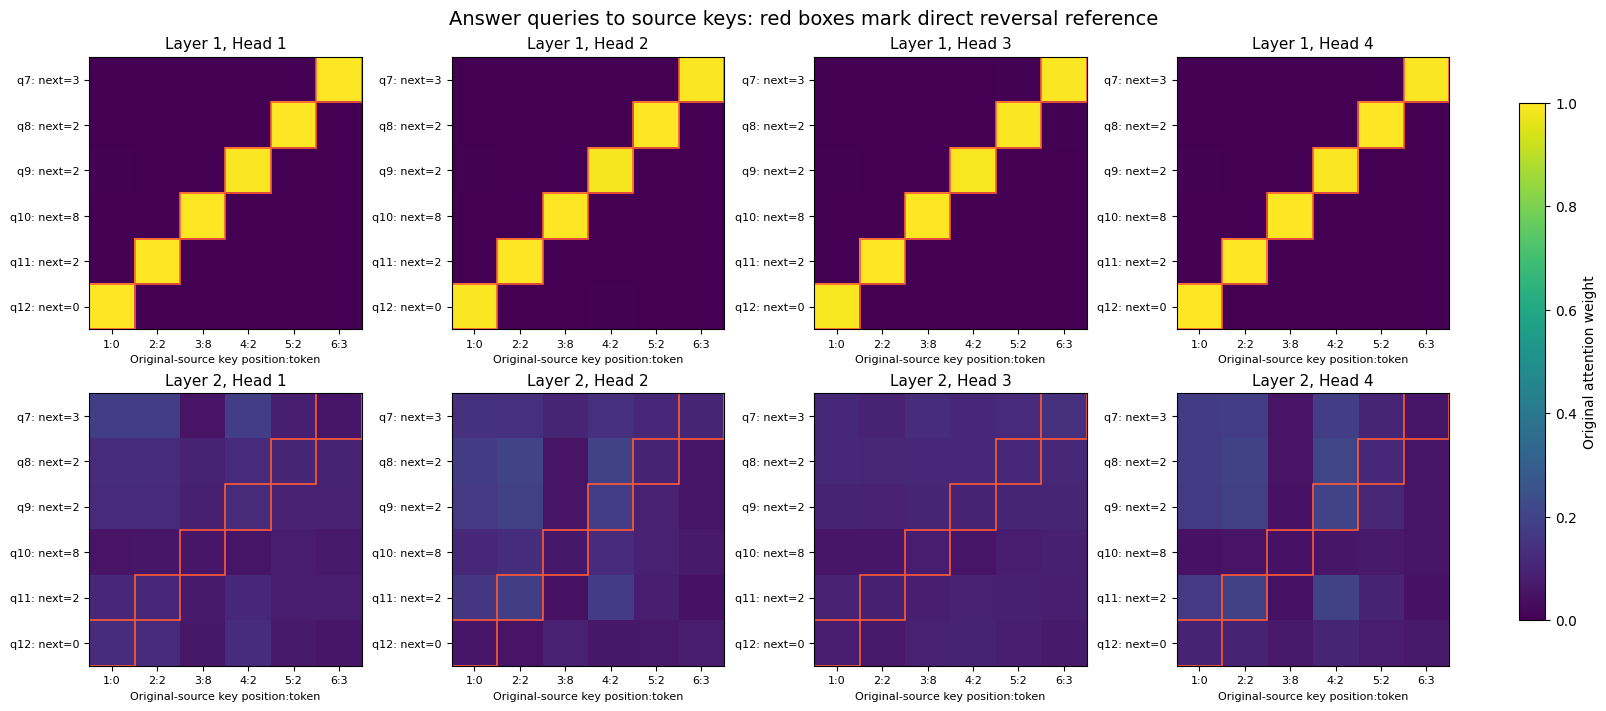

Saved attention_all_heads and attention_reverse_alignment (PNG + PDF).
All panels use [0,1]; cropped panels are NOT renormalized.


In [16]:
# 第 6B 步：完整注意力热图与答案到原题的局部热图
from matplotlib.patches import Rectangle

fig, axes = plt.subplots(num_layers, num_heads, figsize=(17, 8), constrained_layout=True)
for layer in range(num_layers):
    for head in range(num_heads):
        ax = axes[layer, head]
        image = ax.imshow(causal_attention[layer, head], vmin=0, vmax=1,
                          cmap="viridis", interpolation="nearest")
        ax.set_title(f"Layer {layer + 1}, Head {head + 1}", fontsize=11)
        ax.set_xticks(range(vis_len), axis_labels, rotation=90, fontsize=7)
        ax.set_yticks(range(vis_len), axis_labels, fontsize=7)
        ax.set_xlabel("Key position:token", fontsize=9)
        ax.set_ylabel("Query position:token", fontsize=9)
        ax.axhline(PROMPT_LEN - 1.5, color="white", linewidth=0.6, alpha=0.7)
        ax.axvline(PROMPT_LEN - 0.5, color="white", linewidth=0.6, alpha=0.7)
fig.colorbar(image, ax=axes.ravel().tolist(), label="Attention weight", shrink=0.85)
fig.suptitle("Causal attention: same test sample, all layers and heads", fontsize=15)
fig.savefig(OUTPUT_DIR / "attention_all_heads.png", dpi=180, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "attention_all_heads.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)

fig, axes = plt.subplots(num_layers, num_heads, figsize=(16, 7), constrained_layout=True)
source_labels = [axis_labels[k] for k in source_keys]
query_labels = [f"q{q}: next={digit}" for q, digit in zip(answer_queries, expected_answer)]
for layer in range(num_layers):
    for head in range(num_heads):
        ax = axes[layer, head]
        cropped = causal_attention[layer, head][np.ix_(answer_queries, source_keys)]
        image = ax.imshow(cropped, vmin=0, vmax=1, cmap="viridis", interpolation="nearest")
        for output_index in range(SEQ_LEN):
            ax.add_patch(Rectangle((SEQ_LEN - 1 - output_index - 0.5, output_index - 0.5),
                                   1, 1, fill=False, edgecolor="#ff5a36", linewidth=1.2))
        ax.set_title(f"Layer {layer + 1}, Head {head + 1}", fontsize=11)
        ax.set_xticks(range(SEQ_LEN), source_labels, fontsize=8)
        ax.set_yticks(range(SEQ_LEN), query_labels, fontsize=8)
        ax.set_xlabel("Original-source key position:token", fontsize=8)
fig.colorbar(image, ax=axes.ravel().tolist(), label="Original attention weight", shrink=0.85)
fig.suptitle("Answer queries to source keys: red boxes mark direct reversal reference", fontsize=14)
fig.savefig(OUTPUT_DIR / "attention_reverse_alignment.png", dpi=180, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "attention_reverse_alignment.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved attention_all_heads and attention_reverse_alignment (PNG + PDF).")
print("All panels use [0,1]; cropped panels are NOT renormalized.")


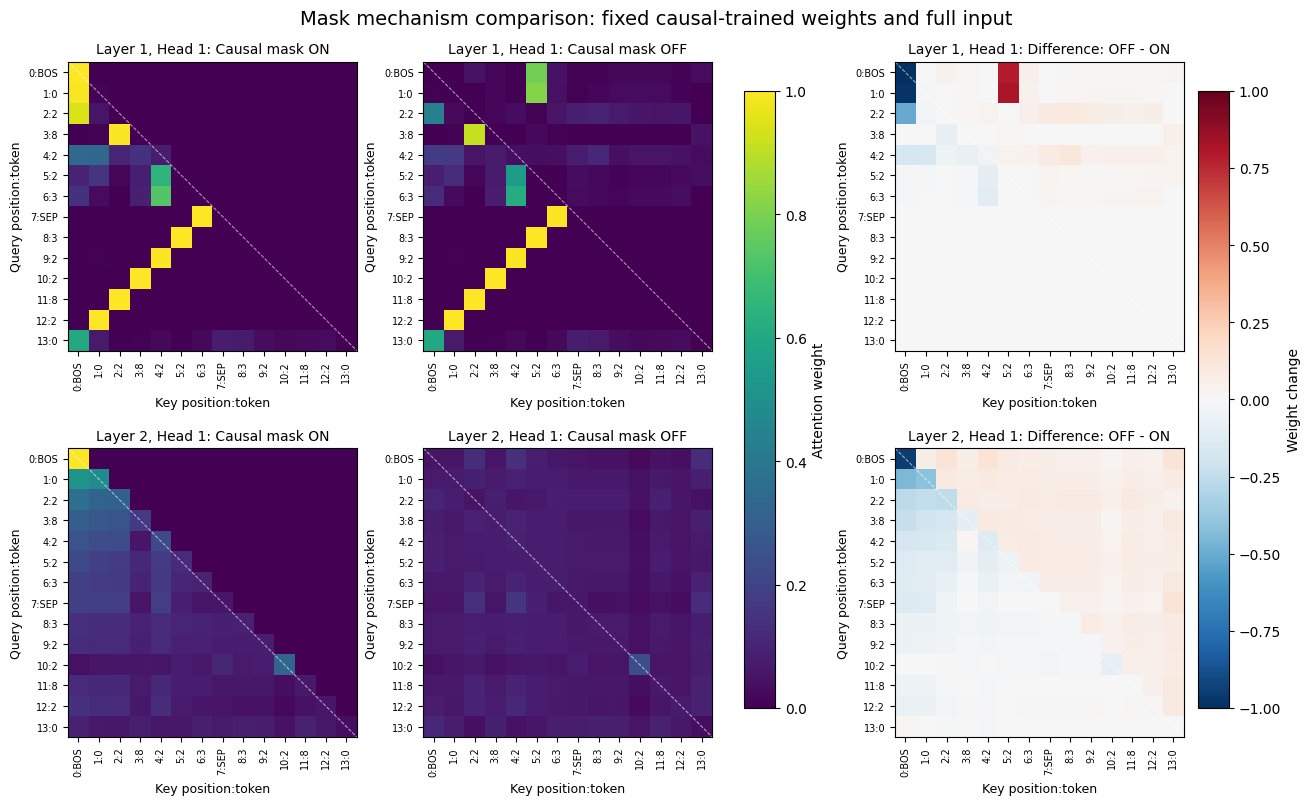

Saved attention_mask_comparison (PNG + PDF).
The diagonal separates past/current keys from future keys above it.
OFF - ON: red=increased weight, blue=decreased weight; shared limits [-1,1].


In [17]:
# 第 6C 步：同一权重、同一输入，仅切换所有层的因果 mask
# 固定每层的第 1 个头，避免为对比图挑选效果最明显的头
COMPARE_HEAD = 0
fig, axes = plt.subplots(num_layers, 3, figsize=(13, 8), constrained_layout=True)
probability_axes, difference_axes = [], []
for layer in range(num_layers):
    matrices = [causal_attention[layer, COMPARE_HEAD],
                unmasked_attention[layer, COMPARE_HEAD],
                unmasked_attention[layer, COMPARE_HEAD] - causal_attention[layer, COMPARE_HEAD]]
    for column, matrix in enumerate(matrices):
        ax = axes[layer, column]
        if column < 2:
            probability_image = ax.imshow(matrix, vmin=0, vmax=1, cmap="viridis", interpolation="nearest")
            probability_axes.append(ax)
        else:
            difference_image = ax.imshow(matrix, vmin=-1, vmax=1, cmap="RdBu_r", interpolation="nearest")
            difference_axes.append(ax)
        mode_name = ["Causal mask ON", "Causal mask OFF", "Difference: OFF - ON"][column]
        ax.set_title(f"Layer {layer + 1}, Head 1: {mode_name}", fontsize=10)
        ax.set_xticks(range(vis_len), axis_labels, rotation=90, fontsize=7)
        ax.set_yticks(range(vis_len), axis_labels, fontsize=7)
        ax.set_xlabel("Key position:token", fontsize=9)
        ax.set_ylabel("Query position:token", fontsize=9)
        ax.plot([-0.5, vis_len - 0.5], [-0.5, vis_len - 0.5], "w--", linewidth=0.7, alpha=0.65)
fig.colorbar(probability_image, ax=probability_axes, label="Attention weight", shrink=0.85)
fig.colorbar(difference_image, ax=difference_axes, label="Weight change", shrink=0.85)
fig.suptitle("Mask mechanism comparison: fixed causal-trained weights and full input", fontsize=14)
fig.savefig(OUTPUT_DIR / "attention_mask_comparison.png", dpi=180, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "attention_mask_comparison.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved attention_mask_comparison (PNG + PDF).")
print("The diagonal separates past/current keys from future keys above it.")
print("OFF - ON: red=increased weight, blue=decreased weight; shared limits [-1,1].")


In [18]:
# 第 6D 步：同一组权重在 mask 开关下的自回归生成与未来扰动
@torch.no_grad()
def generate_with_mask(current_model, prompts, causal):
    current_model.eval()
    tokens = prompts.to(device).clone()
    assert tokens.size(1) == PROMPT_LEN and (tokens[:, -1] == SEP).all()
    finished = torch.zeros(len(tokens), dtype=torch.bool, device=device)
    outputs = []
    for _ in range(SEQ_LEN + 1):
        logits, _ = current_model(tokens, causal=causal)
        next_token = logits[:, -1].argmax(-1)
        next_token = torch.where(finished, torch.full_like(next_token, EOS), next_token)
        outputs.append(next_token)
        finished |= next_token == EOS
        tokens = torch.cat([tokens, next_token[:, None]], dim=1)
    return torch.stack(outputs, dim=1).cpu()

mask_switch_results = []
mask_switch_predictions = {}
source_tensor = torch.tensor(test_sequences, dtype=torch.long)
expected_digits = source_tensor.flip(1)
for use_causal in (True, False):
    predictions = torch.cat([
        generate_with_mask(baseline_model, test_x[start:start + 128, :PROMPT_LEN], use_causal)
        for start in range(0, N_TEST, 128)])
    digit_correct = predictions[:, :SEQ_LEN] == expected_digits
    eos_correct = ((predictions[:, :SEQ_LEN] != EOS).all(1)
                   & (predictions[:, SEQ_LEN] == EOS))
    exact = digit_correct.all(1) & eos_correct
    total_loss, total_targets = 0.0, 0
    with torch.no_grad():
        for start in range(0, N_TEST, 128):
            bx, by = test_x[start:start + 128].to(device), test_y[start:start + 128].to(device)
            logits, _ = baseline_model(bx, causal=use_causal)
            total_loss += F.cross_entropy(logits.reshape(-1, VOCAB_SIZE), by.reshape(-1),
                                           ignore_index=IGNORE_INDEX, reduction="sum").item()
            total_targets += (by != IGNORE_INDEX).sum().item()
    row = dict(inference_causal=use_causal, training_causal=True, training_steps=TRAIN_STEPS,
               correct_digits=int(digit_correct.sum().item()), digit_count=N_TEST * SEQ_LEN,
               token_accuracy=digit_correct.float().mean().item(),
               exact_sequences=int(exact.sum().item()), test_samples=N_TEST,
               sequence_accuracy=exact.float().mean().item(),
               teacher_forced_loss=total_loss / total_targets,
               sample0_generation=format_generation(predictions[VIS_SAMPLE_ID]))
    mask_switch_results.append(row)
    mask_switch_predictions["causal" if use_causal else "unmasked"] = predictions.numpy()
    print(f"Inference mask={'ON' if use_causal else 'OFF'}: "
          f"token={row['token_accuracy']:.2%}, sequence={row['sequence_accuracy']:.2%} "
          f"({row['exact_sequences']}/{N_TEST}), teacher-forced loss={row['teacher_forced_loss']:.6f}")
    print("  Sample 0:", row['sample0_generation'])
assert np.array_equal(mask_switch_predictions["causal"], baseline_predictions.numpy())

changed_vis_input = vis_input.clone()
changed_vis_input[:, PROMPT_LEN:] = (changed_vis_input[:, PROMPT_LEN:] + 1) % 10
with torch.no_grad():
    changed_causal_logits, _ = baseline_model(changed_vis_input, causal=True)
    changed_unmasked_logits, _ = baseline_model(changed_vis_input, causal=False)
    causal_prefix_change = (causal_logits[:, :PROMPT_LEN] - changed_causal_logits[:, :PROMPT_LEN]).abs().max().item()
    unmasked_prefix_change = (unmasked_logits[:, :PROMPT_LEN] - changed_unmasked_logits[:, :PROMPT_LEN]).abs().max().item()
assert causal_prefix_change < 1e-6
assert unmasked_prefix_change > 1e-6
assert all(torch.equal(value, step6_state_before[name])
           for name, value in baseline_model.state_dict().items())
assert baseline_model.config["causal"] is True
step6_results = dict(sample=vis_metadata, head_statistics=attention_statistics,
                     mask_switch=mask_switch_results,
                     future_perturbation=dict(causal_prefix_change=causal_prefix_change,
                                              unmasked_prefix_change=unmasked_prefix_change),
                     weights_unchanged=True,
                     scope="single fixed-length task; same causal-trained weights")
(OUTPUT_DIR / "step6_results.json").write_text(
    json.dumps(step6_results, ensure_ascii=False, indent=2), encoding="utf-8")
with (OUTPUT_DIR / "mask_switch_metrics.csv").open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=list(mask_switch_results[0]))
    writer.writeheader()
    writer.writerows(mask_switch_results)
np.savez_compressed(OUTPUT_DIR / "mask_switch_predictions.npz", **mask_switch_predictions)
print(f"\nFuture-input perturbation: mask ON prefix change={causal_prefix_change:.6f}")
print(f"Future-input perturbation: mask OFF prefix change={unmasked_prefix_change:.6f}")
print("PASS: all model weights remain exactly unchanged; causal defaults retained.")
print("Note: mask switching after causal training is separate from training without a mask.")


Inference mask=ON: token=100.00%, sequence=100.00% (512/512), teacher-forced loss=0.000245
  Sample 0: 3 2 2 8 2 0 <EOS>
Inference mask=OFF: token=100.00%, sequence=100.00% (512/512), teacher-forced loss=0.000247
  Sample 0: 3 2 2 8 2 0 <EOS>

Future-input perturbation: mask ON prefix change=0.000000
Future-input perturbation: mask OFF prefix change=1.071323
PASS: all model weights remain exactly unchanged; causal defaults retained.
Note: mask switching after causal training is separate from training without a mask.


In [19]:
# 第 6E 步：记录真实观察，导出图表、原始矩阵和指标
import zipfile
import hashlib
import base64
from IPython.display import HTML, Markdown, display

layer_alignment = [float(np.mean([r['expected_source_alignment']
                    for r in attention_statistics if r['mode'] == 'causal' and r['layer'] == layer]))
                   for layer in range(1, num_layers + 1)]
summary_markdown = f"""### 第六步观察结果

同一模型权重、同一测试样本，各图采用统一颜色范围。局部图保留原始权重。

- 第一层平均直接反转对齐权重：**{layer_alignment[0]:.2%}**；第二层为 **{layer_alignment[1]:.2%}**。
- 第一层在这条样本上形成清晰的反向位置对齐；第二层分布更分散。各头的重要性还需要其他实验判断。
- 开启 mask 时未来权重严格为 0；关闭后未来位置获得非零权重，信息可见范围改变。

|同一模型的推理设置|数字准确率|整序列准确率（含 EOS）|测试教师强制 loss|
|---|---:|---:|---:|
|mask 开启|{mask_switch_results[0]['token_accuracy']:.2%}|{mask_switch_results[0]['sequence_accuracy']:.2%}|{mask_switch_results[0]['teacher_forced_loss']:.6f}|
|mask 关闭|{mask_switch_results[1]['token_accuracy']:.2%}|{mask_switch_results[1]['sequence_accuracy']:.2%}|{mask_switch_results[1]['teacher_forced_loss']:.6f}|

修改未来答案输入后的前缀分数最大变化：mask 开启 **{causal_prefix_change:.6f}**，关闭 **{unmasked_prefix_change:.6f}**。

本次仅切换已经采用因果 mask 训练的模型。关闭 mask 后信息流变化，而当前固定长度测试集的贪心预测仍保持正确。第七步将从头训练无 mask 模型，单独比较训练条件。全部参数已逐项验证保持不变。
"""
(OUTPUT_DIR / 'step6_summary.md').write_text(summary_markdown, encoding='utf-8')
display(Markdown(summary_markdown))

step6_names = ['attention_all_heads.png', 'attention_all_heads.pdf',
               'attention_reverse_alignment.png', 'attention_reverse_alignment.pdf',
               'attention_mask_comparison.png', 'attention_mask_comparison.pdf',
               'attention_sample0.npz', 'attention_sample0.json', 'attention_statistics.csv',
               'mask_switch_metrics.csv', 'mask_switch_predictions.npz',
               'step6_results.json', 'step6_summary.md']
step6_hashes = {name: hashlib.sha256((OUTPUT_DIR / name).read_bytes()).hexdigest()
                for name in step6_names}
STEP6_ZIP = Path('/content/experiment1_step6_results.zip')
with zipfile.ZipFile(STEP6_ZIP, 'w', zipfile.ZIP_DEFLATED) as archive:
    for name in step6_names:
        archive.write(OUTPUT_DIR / name, arcname=name)
    archive.writestr('SHA256.json', json.dumps(step6_hashes, indent=2))
with zipfile.ZipFile(STEP6_ZIP) as archive:
    assert archive.testzip() is None
print(f"Export verified: {len(step6_names)} files; {STEP6_ZIP.stat().st_size / 1024:.1f} KiB")
print("第六步图表与原始数据已保存，最终提交包统一包含。")


### 第六步观察结果

同一模型权重、同一测试样本，各图采用统一颜色范围。局部图保留原始权重。

- 第一层平均直接反转对齐权重：**99.64%**；第二层为 **10.71%**。
- 第一层在这条样本上形成清晰的反向位置对齐；第二层分布更分散。各头的重要性还需要其他实验判断。
- 开启 mask 时未来权重严格为 0；关闭后未来位置获得非零权重，信息可见范围改变。

|同一模型的推理设置|数字准确率|整序列准确率（含 EOS）|测试教师强制 loss|
|---|---:|---:|---:|
|mask 开启|100.00%|100.00%|0.000245|
|mask 关闭|100.00%|100.00%|0.000247|

修改未来答案输入后的前缀分数最大变化：mask 开启 **0.000000**，关闭 **1.071323**。

本次仅切换已经采用因果 mask 训练的模型。关闭 mask 后信息流变化，而当前固定长度测试集的贪心预测仍保持正确。第七步将从头训练无 mask 模型，单独比较训练条件。全部参数已逐项验证保持不变。


Export verified: 13 files; 474.9 KiB
第六步图表与原始数据已保存，最终提交包统一包含。


## 第 7 步：从头训练单头与无因果 mask 模型，完成消融

### 实验组与控制变量

|配置|层数|隐藏维度|头数|训练和推理 mask|
|---|---:|---:|---:|---|
|完整模型 baseline|2|64|4|开启|
|单头 single_head|2|64|1|开启|
|无 mask no_mask|2|64|4|关闭|

单头的每头维度为 64，四头的每头维度为 16。三组都保留相同尺寸的 Q/K/V 和输出投影，因此总参数量相同。两组消融均从固定种子 42 重新初始化；检查其初始参数与同种子的完整模型逐项相等。

训练集、验证集、测试集、抽样顺序、训练步数、batch size、优化器、学习率、梯度裁剪及评估代码全部复用第 5 步。固定训练 600 步，选择最后一步模型；不根据测试结果重新调参。正式基准模型的已训练参数保持不变。

### 观察什么

- 单头与四头比较注意力头数在本次短序列任务上的影响。
- 无 mask 训练允许读取未来位置，错位输入中包含下一个位置上的正确答案；教师强制 loss 需要结合独立自回归生成结果解读。
- 自回归生成只输入题目；六个数字的 Token 准确率和含正确 EOS 的整序列准确率继续按相同口径计算。
- 本步从头训练无 mask 模型；第 6 步是在已经采用 mask 训练的权重上临时切换 mask，两项实验分别记录。

结果表包含参数量、头数、mask、训练步数、最终 train/validation loss、测试教师强制 loss、生成准确率和训练时间。训练时间为单次墙钟时间，包含验证及检查点保存，受运行环境波动影响。本轮使用一个随机种子，结论限定在当前固定长度任务和本次运行。


In [20]:
# 第 7A 步：核对相同数据、抽样顺序和初始化；创建两个全新模型
import hashlib
assert "baseline_model" in globals() and "train_model" in globals()
assert TRAIN_STEPS == baseline_metrics['training_steps'] and TRAIN_STEPS > 0
assert MODEL_CONFIG['dropout'] == 0.0
assert json.loads((OUTPUT_DIR / 'training_config.json').read_text()) == TRAIN_CONFIG
with np.load(OUTPUT_DIR / 'data_and_schedule.npz') as saved_data:
    assert np.array_equal(saved_data['train'], np.array(train_sequences))
    assert np.array_equal(saved_data['validation'], np.array(val_sequences))
    assert np.array_equal(saved_data['test'], np.array(test_sequences))
    assert np.array_equal(saved_data['batch_schedule'], batch_schedule.numpy())

def model_weight_hash(current_model):
    digest = hashlib.sha256()
    for name, tensor in sorted(current_model.state_dict().items()):
        digest.update(name.encode('utf-8'))
        digest.update(tensor.detach().cpu().contiguous().numpy().tobytes())
    return digest.hexdigest()

baseline_hash_before_ablation = model_weight_hash(baseline_model)
initial_reference = make_model(num_heads=4, causal=True, seed=SEED)
single_head_model = make_model(num_heads=1, causal=True, seed=SEED)
no_mask_model = make_model(num_heads=4, causal=False, seed=SEED)
initial_hash = model_weight_hash(initial_reference)
assert model_weight_hash(single_head_model) == initial_hash
assert model_weight_hash(no_mask_model) == initial_hash
parameter_count = sum(p.numel() for p in initial_reference.parameters())
assert parameter_count == baseline_metrics['parameters']
for current_model in (single_head_model, no_mask_model):
    assert sum(p.numel() for p in current_model.parameters()) == parameter_count
    assert all(p.grad is None for p in current_model.parameters())
assert single_head_model.config['num_heads'] == 1
assert single_head_model.config['causal'] is True
assert no_mask_model.config['num_heads'] == 4
assert no_mask_model.config['causal'] is False
controls = dict(seed=SEED, steps=TRAIN_STEPS, batch_size=BATCH_SIZE,
                learning_rate=LEARNING_RATE, clip_norm=CLIP_NORM,
                parameters=parameter_count, shared_initial_weight_hash=initial_hash,
                schedule_sha256=hashlib.sha256(batch_schedule.numpy().tobytes()).hexdigest(),
                dataset_archive_sha256=hashlib.sha256((OUTPUT_DIR / 'data_and_schedule.npz').read_bytes()).hexdigest(),
                baseline_weight_hash=baseline_hash_before_ablation,
                data_and_schedule_verified=True)
(OUTPUT_DIR / 'ablation_controls.json').write_text(
    json.dumps(controls, ensure_ascii=False, indent=2), encoding='utf-8')
del initial_reference
print(f'PASS: same datasets, {TRAIN_STEPS} steps, and exactly the same sample indices at each step.')
print('PASS: fresh single-head and no-mask models share the baseline initialization.')
print(f'Parameters per model: {parameter_count}; hidden dimension remains 64.')
print('Single-head: 1 head x 64 dimensions, causal=True')
print('No-mask: 4 heads x 16 dimensions, causal=False throughout training and generation')
print('Baseline trained weights preserved; both ablations start from scratch.')


PASS: same datasets, 600 steps, and exactly the same sample indices at each step.
PASS: fresh single-head and no-mask models share the baseline initialization.
Parameters per model: 69709; hidden dimension remains 64.
Single-head: 1 head x 64 dimensions, causal=True
No-mask: 4 heads x 16 dimensions, causal=False throughout training and generation
Baseline trained weights preserved; both ablations start from scratch.


In [21]:
# 第 7B 步：单头模型从头训练 600 步，再进行独立自回归测试
single_head_model = make_model(num_heads=1, causal=True, seed=SEED)
assert model_weight_hash(single_head_model) == initial_hash
single_head_history, single_head_batch_losses, single_head_training_seconds = train_model(
    single_head_model, 'single_head')
single_head_metrics, single_head_predictions, single_head_prediction_rows = evaluate_model(
    single_head_model, 'single_head', single_head_training_seconds)
experiment_results['single_head'] = single_head_metrics


single_head: step   0/600 | train loss 2.592741 | val loss 2.596876
single_head: step  50/600 | train loss 0.011299 | val loss 0.011328
single_head: step 100/600 | train loss 0.003256 | val loss 0.003261
single_head: step 150/600 | train loss 0.002031 | val loss 0.002034
single_head: step 200/600 | train loss 0.001394 | val loss 0.001396
single_head: step 250/600 | train loss 0.001017 | val loss 0.001018
single_head: step 300/600 | train loss 0.000776 | val loss 0.000777
single_head: step 350/600 | train loss 0.000613 | val loss 0.000614
single_head: step 400/600 | train loss 0.000497 | val loss 0.000498
single_head: step 450/600 | train loss 0.000412 | val loss 0.000412
single_head: step 500/600 | train loss 0.000347 | val loss 0.000347
single_head: step 550/600 | train loss 0.000296 | val loss 0.000297
single_head: step 600/600 | train loss 0.000256 | val loss 0.000257
Finished single_head: 4.67 seconds including evaluation/checkpoints
single_head: independent test set, greedy autore

In [22]:
# 第 7C 步：无 mask 模型从头训练，训练与生成均关闭 mask
no_mask_model = make_model(num_heads=4, causal=False, seed=SEED)
assert model_weight_hash(no_mask_model) == initial_hash
no_mask_history, no_mask_batch_losses, no_mask_training_seconds = train_model(
    no_mask_model, 'no_mask')
no_mask_metrics, no_mask_predictions, no_mask_prediction_rows = evaluate_model(
    no_mask_model, 'no_mask', no_mask_training_seconds)
experiment_results['no_mask'] = no_mask_metrics
assert model_weight_hash(baseline_model) == baseline_hash_before_ablation
print('\nPASS: baseline model weights remain unchanged after both ablations.')


no_mask: step   0/600 | train loss 2.591619 | val loss 2.595482
no_mask: step  50/600 | train loss 0.009129 | val loss 0.009171
no_mask: step 100/600 | train loss 0.002818 | val loss 0.002826
no_mask: step 150/600 | train loss 0.001786 | val loss 0.001790
no_mask: step 200/600 | train loss 0.001236 | val loss 0.001239
no_mask: step 250/600 | train loss 0.000907 | val loss 0.000909
no_mask: step 300/600 | train loss 0.000695 | val loss 0.000697
no_mask: step 350/600 | train loss 0.000551 | val loss 0.000552
no_mask: step 400/600 | train loss 0.000448 | val loss 0.000449
no_mask: step 450/600 | train loss 0.000371 | val loss 0.000372
no_mask: step 500/600 | train loss 0.000313 | val loss 0.000314
no_mask: step 550/600 | train loss 0.000268 | val loss 0.000269
no_mask: step 600/600 | train loss 0.000232 | val loss 0.000233
Finished no_mask: 4.62 seconds including evaluation/checkpoints
no_mask: independent test set, greedy autoregressive generation
Token accuracy (6 digits): 100.00% (3072

In [23]:
# 第 7D 步：生成三组消融结果表，并检查同一样本的对齐模式
from IPython.display import Markdown, display
ablation_order = ['baseline', 'single_head', 'no_mask']
ablation_labels = {'baseline': '完整模型', 'single_head': '单头', 'no_mask': '无 mask'}
ablation_models = {'baseline': baseline_model, 'single_head': single_head_model, 'no_mask': no_mask_model}
ablation_histories = {'baseline': baseline_history, 'single_head': single_head_history, 'no_mask': no_mask_history}
ablation_predictions = {'baseline': baseline_predictions, 'single_head': single_head_predictions, 'no_mask': no_mask_predictions}
ablation_rows, alignment_diagnostics = [], []
for name in ablation_order:
    metrics = experiment_results[name].copy()
    current_model = ablation_models[name]
    history = ablation_histories[name]
    assert history[-1]['step'] == metrics['training_steps'] == TRAIN_STEPS
    assert metrics['parameters'] == parameter_count
    metrics.update(final_train_loss=history[-1]['train_loss'],
                   final_validation_loss=history[-1]['val_loss'],
                   d_model=current_model.config['d_model'],
                   num_layers=current_model.config['num_layers'])
    ablation_rows.append(metrics)
    current_model.eval()
    with torch.no_grad():
        _, maps = current_model(test_x[:1].to(device), return_attention=True)
    matrix = maps[0][0].detach().cpu().numpy()
    diagnostic = dict(experiment=name, sample_id=0,
                      first_layer_source_alignment=float(matrix[:, answer_queries, expected_keys].mean()),
                      first_layer_next_answer_weight=float(matrix[:, answer_queries, answer_queries + 1].mean()),
                      first_layer_answer_future_mass=float((matrix[:, answer_queries, :]
                          * future_positions[answer_queries]).sum(-1).mean()))
    alignment_diagnostics.append(diagnostic)

assert model_weight_hash(baseline_model) == baseline_hash_before_ablation
assert hashlib.sha256(batch_schedule.numpy().tobytes()).hexdigest() == controls['schedule_sha256']
with (OUTPUT_DIR / 'ablation_results.csv').open('w', newline='', encoding='utf-8-sig') as file:
    writer = csv.DictWriter(file, fieldnames=list(ablation_rows[0]))
    writer.writeheader()
    writer.writerows(ablation_rows)
(OUTPUT_DIR / 'ablation_results.json').write_text(
    json.dumps(ablation_rows, ensure_ascii=False, indent=2), encoding='utf-8')
(OUTPUT_DIR / 'ablation_alignment_diagnostics.json').write_text(
    json.dumps(alignment_diagnostics, ensure_ascii=False, indent=2), encoding='utf-8')

table_lines = ['### 消融结果表', '',
               '|配置|头数|mask|参数|步数|测试 loss|数字准确率|整序列准确率|训练秒|',
               '|---|---:|---|---:|---:|---:|---:|---:|---:|']
for row in ablation_rows:
    table_lines.append(
        f"|{ablation_labels[row['experiment']]}|{row['num_heads']}|"
        f"{'开启' if row['causal'] else '关闭'}|{row['parameters']}|{row['training_steps']}|"
        f"{row['test_teacher_forced_loss']:.6f}|{row['token_accuracy']:.2%}|"
        f"{row['sequence_accuracy']:.2%}|{row['training_seconds']:.2f}|")
table_markdown = '\n'.join(table_lines)
display(Markdown(table_markdown))
print('Test loss = teacher-forced answer + EOS cross-entropy; generation uses question only.')
print('Training seconds include evaluation/checkpoints and are single-run wall-clock measurements.')
print('\nSample 0, first-layer direct source alignment / immediate future-answer weight:')
for row in alignment_diagnostics:
    print(f"{row['experiment']:12s}: source alignment={row['first_layer_source_alignment']:.2%}, "
          f"next-answer weight={row['first_layer_next_answer_weight']:.2%}")

if all(row['sequence_accuracy'] == 1.0 for row in ablation_rows):
    finding = ('三组均达到 512/512 的整序列准确率，本次固定长度任务出现准确率饱和。'
               '当前单一随机种子的结果未显示四头相对单头的生成准确率优势，也未观察到无 mask 模型的生成失败。')
else:
    finding = ('三组真实生成指标见表。结合训练条件、教师强制 loss 和独立生成结果解读差异。')
summary = (table_markdown + '\n\n' + finding + '\n\n'
           '三组数据、抽样顺序、步数、隐藏维度及参数量一致；两组消融均从相同初始参数重新训练。'
           '无 mask 教师强制计算可读取未来信息，因此其 loss 采用了不同的信息条件，'
           '更低的数值不能直接解释为更强的自回归生成能力。\n\n'
           '第一层对齐诊断仅描述测试样本 0 的权重分配，不作为因果重要性证明。'
           '结论限定在长度为 6 的数字反转、当前数据划分和种子 42；单次计时不构成性能基准。\n')
(OUTPUT_DIR / 'ablation_results.md').write_text(summary, encoding='utf-8')
display(Markdown('**本次结论：**' + finding))
print('\nSaved ablation_results.csv / .json / .md and alignment diagnostics.')


### 消融结果表

|配置|头数|mask|参数|步数|测试 loss|数字准确率|整序列准确率|训练秒|
|---|---:|---|---:|---:|---:|---:|---:|---:|
|完整模型|4|开启|69709|600|0.000245|100.00%|100.00%|11.02|
|单头|1|开启|69709|600|0.000257|100.00%|100.00%|4.67|
|无 mask|4|关闭|69709|600|0.000232|100.00%|100.00%|4.62|

Test loss = teacher-forced answer + EOS cross-entropy; generation uses question only.
Training seconds include evaluation/checkpoints and are single-run wall-clock measurements.

Sample 0, first-layer direct source alignment / immediate future-answer weight:
baseline    : source alignment=99.64%, next-answer weight=0.00%
single_head : source alignment=99.82%, next-answer weight=0.00%
no_mask     : source alignment=71.13%, next-answer weight=28.16%


**本次结论：**三组均达到 512/512 的整序列准确率，本次固定长度任务出现准确率饱和。当前单一随机种子的结果未显示四头相对单头的生成准确率优势，也未观察到无 mask 模型的生成失败。


Saved ablation_results.csv / .json / .md and alignment diagnostics.


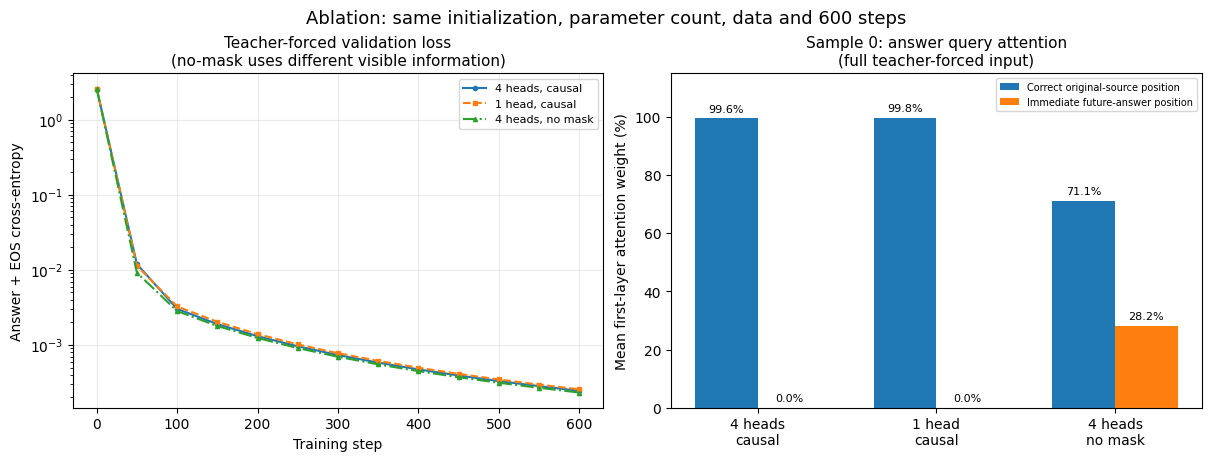



### 同一样本的补充观察

测试样本 0 的无 mask 模型第一层，对正确原题位置的平均注意力为 71.13%，对紧邻未来答案位置为 28.16%。这显示完整教师强制输入下存在未来答案信息读取；同时，独立自回归测试仍全部正确。注意力分配改变与最终准确率差异分别记录，不据此预设无 mask 一定失败。


Saved ablation_comparison.png / .pdf; updated ablation_results.md.


In [24]:
# 第 7E 步：比较收敛曲线与注意力分配，并补充定量观察
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
plot_labels = {'baseline': '4 heads, causal', 'single_head': '1 head, causal', 'no_mask': '4 heads, no mask'}
for name, style in zip(ablation_order, ['o-', 's--', '^-.']):
    history = ablation_histories[name]
    axes[0].plot([row['step'] for row in history], [row['val_loss'] for row in history],
                 style, markersize=3, label=plot_labels[name])
axes[0].set_yscale('log')
axes[0].set_xlabel('Training step')
axes[0].set_ylabel('Answer + EOS cross-entropy')
axes[0].set_title('Teacher-forced validation loss\n(no-mask uses different visible information)', fontsize=11)
axes[0].grid(True, alpha=0.25)
axes[0].legend(fontsize=8)
x_positions = np.arange(3)
width = 0.35
source_values = [row['first_layer_source_alignment'] * 100 for row in alignment_diagnostics]
future_values = [row['first_layer_next_answer_weight'] * 100 for row in alignment_diagnostics]
source_bars = axes[1].bar(x_positions - width / 2, source_values, width,
                         label='Correct original-source position')
future_bars = axes[1].bar(x_positions + width / 2, future_values, width,
                         label='Immediate future-answer position')
for bars in (source_bars, future_bars):
    axes[1].bar_label(bars, fmt='%.1f%%', padding=3, fontsize=8)
axes[1].set_xticks(x_positions, ['4 heads\ncausal', '1 head\ncausal', '4 heads\nno mask'])
axes[1].set_ylim(0, 115)
axes[1].set_ylabel('Mean first-layer attention weight (%)')
axes[1].set_title('Sample 0: answer query attention\n(full teacher-forced input)', fontsize=11)
axes[1].legend(fontsize=7, loc='upper right')
fig.suptitle(f'Ablation: same initialization, parameter count, data and {TRAIN_STEPS} steps', fontsize=13)
fig.savefig(OUTPUT_DIR / 'ablation_comparison.png', dpi=180, bbox_inches='tight')
fig.savefig(OUTPUT_DIR / 'ablation_comparison.pdf', bbox_inches='tight')
plt.show()
plt.close(fig)

no_mask_diagnostic = alignment_diagnostics[2]
diagnostic_note = (
    '\n\n### 同一样本的补充观察\n\n'
    f"测试样本 0 的无 mask 模型第一层，对正确原题位置的平均注意力为 {no_mask_diagnostic['first_layer_source_alignment']:.2%}，"
    f"对紧邻未来答案位置为 {no_mask_diagnostic['first_layer_next_answer_weight']:.2%}。"
    '这显示完整教师强制输入下存在未来答案信息读取；同时，独立自回归测试仍全部正确。'
    '注意力分配改变与最终准确率差异分别记录，不据此预设无 mask 一定失败。\n')
summary = summary.split('\n\n### 同一样本的补充观察')[0] + diagnostic_note
(OUTPUT_DIR / 'ablation_results.md').write_text(summary, encoding='utf-8')
display(Markdown(diagnostic_note))
print('Saved ablation_comparison.png / .pdf; updated ablation_results.md.')


In [25]:
# 第 7F 步：验证三组权重重载，导出消融实验完整记录
import zipfile
import base64
from IPython.display import HTML, display
reload_records = []
for name in ablation_order:
    checkpoint = torch.load(OUTPUT_DIR / f'{name}_final.pt', map_location=device, weights_only=True)
    reloaded = ToyTransformer(**checkpoint['model_config']).to(device)
    reloaded.load_state_dict(checkpoint['model_state'])
    reloaded.eval()
    original_hash = model_weight_hash(ablation_models[name])
    assert model_weight_hash(reloaded) == original_hash
    regenerated = generate_answers(reloaded, test_x[:32, :PROMPT_LEN])
    assert torch.equal(regenerated, ablation_predictions[name][:32])
    reload_records.append(dict(experiment=name, weights_match=True,
                               first_32_generations_match=True, trained_weight_sha256=original_hash))
    print(f'PASS: {name} saved weights reload exactly; first 32 generations match.')
assert model_weight_hash(baseline_model) == baseline_hash_before_ablation
(OUTPUT_DIR / 'ablation_reload_checks.json').write_text(
    json.dumps(reload_records, indent=2), encoding='utf-8')

selected_names = ['training_config.json', 'data_and_schedule.npz', 'environment.json',
                  'ablation_controls.json', 'ablation_results.csv', 'ablation_results.json',
                  'ablation_results.md', 'ablation_alignment_diagnostics.json',
                  'ablation_comparison.png', 'ablation_comparison.pdf', 'ablation_reload_checks.json']
for name in ablation_order:
    for suffix in ['final.pt', 'history.csv', 'history.json', 'batch_losses.json',
                   'metrics.json', 'predictions.csv', 'predictions.npz']:
        selected_names.append(f'{name}_{suffix}')
assert len(selected_names) == len(set(selected_names))
export_hashes = {name: hashlib.sha256((OUTPUT_DIR / name).read_bytes()).hexdigest()
                 for name in selected_names}
STEP7_ZIP = Path('/content/experiment1_step7_ablation.zip')
with zipfile.ZipFile(STEP7_ZIP, 'w', zipfile.ZIP_DEFLATED) as archive:
    for name in selected_names:
        archive.write(OUTPUT_DIR / name, arcname=name)
    archive.writestr('SHA256.json', json.dumps(export_hashes, indent=2))
with zipfile.ZipFile(STEP7_ZIP) as archive:
    assert archive.testzip() is None
print(f'Export verified: {len(selected_names)} files; {STEP7_ZIP.stat().st_size / 1024:.1f} KiB')
print('Includes all three final model weights, predictions, training logs, result tables, and comparison plots.')
print('Notebook code and outputs are saved separately in Google Drive.')
print("第七步消融结果与权重已保存，最终提交包统一包含。")


PASS: baseline saved weights reload exactly; first 32 generations match.
PASS: single_head saved weights reload exactly; first 32 generations match.
PASS: no_mask saved weights reload exactly; first 32 generations match.
Export verified: 32 files; 1103.1 KiB
Includes all three final model weights, predictions, training logs, result tables, and comparison plots.
Notebook code and outputs are saved separately in Google Drive.
第七步消融结果与权重已保存，最终提交包统一包含。


PASS: report values read from current artifacts; all 3 prediction CSV files independently verified.
PASS: all 5 PNG/PDF figure pairs present.
Report: 实验一_第24组_庄隆生_杨全海_林艺旻_谢伯劲_报告.md | 4831 characters


# 实验一：手写注意力机制与 Decoder-only Transformer

组别：第24组  
成员：庄隆生、杨全海、林艺旻、谢伯劲  
平台：Google Colab 免费版；本次设备：Tesla T4  
结果来源：本 notebook 当前从头运行产生的 JSON、CSV、权重和图表。

## 1. 实验目的

手写缩放点积注意力、多头自注意力和因果 mask，理解张量的拆头、拼头与信息可见范围；构建包含位置编码、残差、LayerNorm 和前馈网络的两层 Decoder-only Transformer，学习数字序列反转，并通过注意力图和消融实验分析模型行为。

## 2. 数据与监督方式

固定种子 42，从 0–9 组成的长度 6 序列中无重复抽样，训练 4096 条、验证 256 条、测试 512 条，三者没有交集。保留前导零，词表含数字和 BOS、SEP、EOS 共 13 个 token。

示例：`<BOS> 3 1 4 2 0 5 <SEP> 5 0 2 4 1 3 <EOS>`。
完整序列长 15；训练输入和标签错开一位，均为 `[B,14]`。标签前 7 个位置为 -100，仅计算六个答案数字及 EOS 的交叉熵。输入位置 7 的 SEP 预测第一个答案数字。

训练使用教师强制输入；评估生成只提供 `[BOS]+六个原题数字+[SEP]`，在 eval 和无梯度模式下逐个贪心生成 7 个 token，不输入标准答案，也不限制输出必须为数字。

## 3. 方法与张量形状

令 Q=XW_Q、K=XW_K、V=XW_V，注意力为 `softmax(QK^T/sqrt(d_head)+M)V`。因果 mask 将未来位置分数设为负无穷，对角线保留。softmax 沿 key 维计算，每行权重和为 1。

四头配置中，输入为 `[B,T,64]`，Q/K/V 拆为 `[B,4,T,16]`；注意力矩阵为 `[B,4,T,T]`；加权求和后拼回 `[B,T,64]` 并进行输出投影。单头配置为 `[B,1,T,64]`。Q/K/V、拆头、缩放、mask、softmax、加权、拼头及输出投影均手写；PyTorch 官方 MultiheadAttention 仅用于独立数值验证。

模型使用 token embedding 与可学习位置编码，2 个 Pre-LayerNorm block，每个 block 为“LN→注意力→残差”和“LN→线性64→128→GELU→线性128→64→残差”，末尾 LN 和 13 类输出层。dropout 为 0。

## 4. 配置与验证

三组隐藏维度 64、前馈维度 128、层数 2、参数量 69709；Adam 学习率 0.003，batch size 64，梯度裁剪 1，统一训练 600 步，采用最后一步模型。测速模型丢弃，正式训练从种子 42 初始化；数据抽样种子 142、逐步样本索引完全共用。每次记录 loss 都在 eval 模式下计算完整训练集与验证集的目标区间平均交叉熵。

本次环境：Python 3.13.16，PyTorch 2.11.0+cu130，NumPy 2.1.3，Matplotlib 3.10.0。无需额外安装或付费服务。

检查覆盖数据唯一性、错位标签、每条 7 个监督目标、注意力形状、逐行归一化、未来权重为零、改变未来 token 后因果前缀不变、官方数值对照、有限梯度与一次参数更新。消融控制还校验初始权重、数据和抽样顺序的哈希；保存后的三组权重重新加载并核对前 32 条生成。预测 CSV 的 512 条记录再次独立按原题反转重算指标。

## 5. Loss 与真实生成

| 模型 | 初始训练 loss | 最终训练 loss | 最终验证 loss |
| --- | --- | --- | --- |
| 完整模型 | 2.592788 | 0.00024482 | 0.00024496 |
| 单头模型 | 2.592741 | 0.00025636 | 0.00025661 |
| 无 mask 模型 | 2.591619 | 0.00023207 | 0.00023254 |

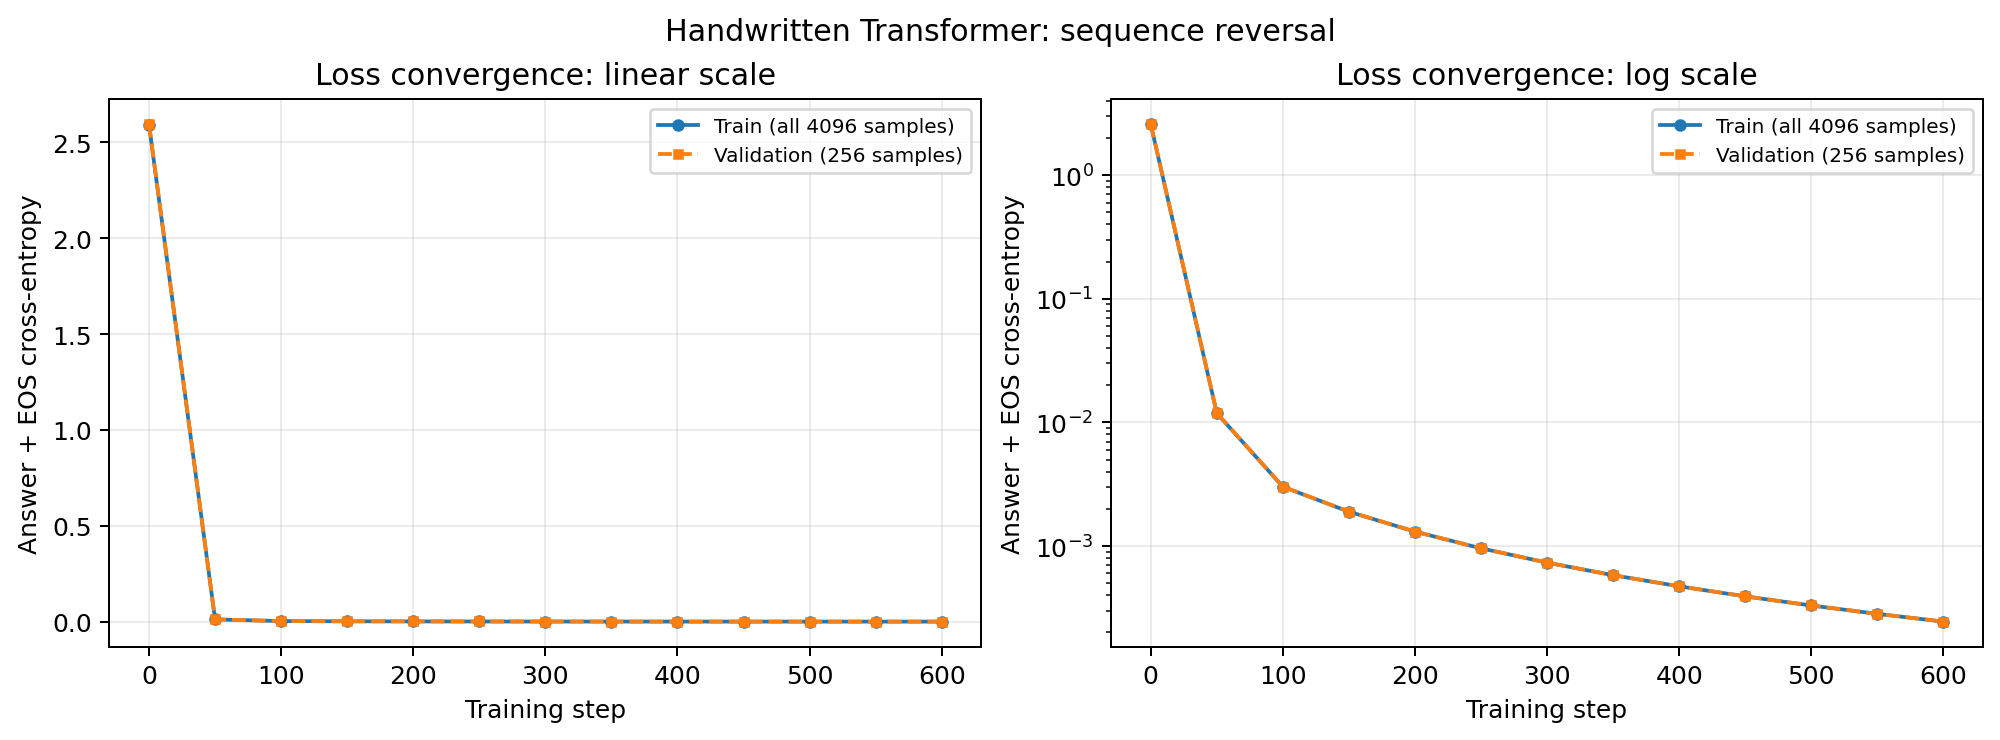

完整模型测试数字准确率为 100.00%（3072/3072），整序列准确率为 100.00%（512/512）。整序列要求六个数字全对且第 7 个输出正确为 EOS；提前结束或输出特殊符号造成的数字缺失算错。教师强制测试 loss 为 0.00024506。

| 测试编号 | 原题 | 正确答案 | 完整模型生成 |
| --- | --- | --- | --- |
| 0 | 0 2 8 2 2 3 | 3 2 2 8 2 0 <EOS> | 3 2 2 8 2 0 <EOS> |
| 1 | 9 9 9 2 9 7 | 7 9 2 9 9 9 <EOS> | 7 9 2 9 9 9 <EOS> |
| 2 | 7 6 2 5 3 8 | 8 3 5 2 6 7 <EOS> | 8 3 5 2 6 7 <EOS> |
| 3 | 4 8 4 0 4 5 | 5 4 0 4 8 4 <EOS> | 5 4 0 4 8 4 <EOS> |
| 4 | 9 8 8 7 8 0 | 0 8 7 8 8 9 <EOS> | 0 8 7 8 8 9 <EOS> |

完整模型在本次独立测试集中有 0 条错误。未找到错误样例，报告不虚构错误；完整预测保存在 baseline_predictions.csv。

## 6. 不同层、不同头的注意力

展示固定测试样本 0，题目为 `0 2 8 2 2 3`。热图纵轴是 query，横轴是 key，标签同时给出位置与 token，颜色表示原始注意力权重，使用统一范围 0–1。query 位置 i 的表示预测 token i+1，因此六个答案的 query 为 7–12，其正确原题 key 位置依次为 6、5、4、3、2、1；相同数字也按位置区分。局部反转图不重新归一化。

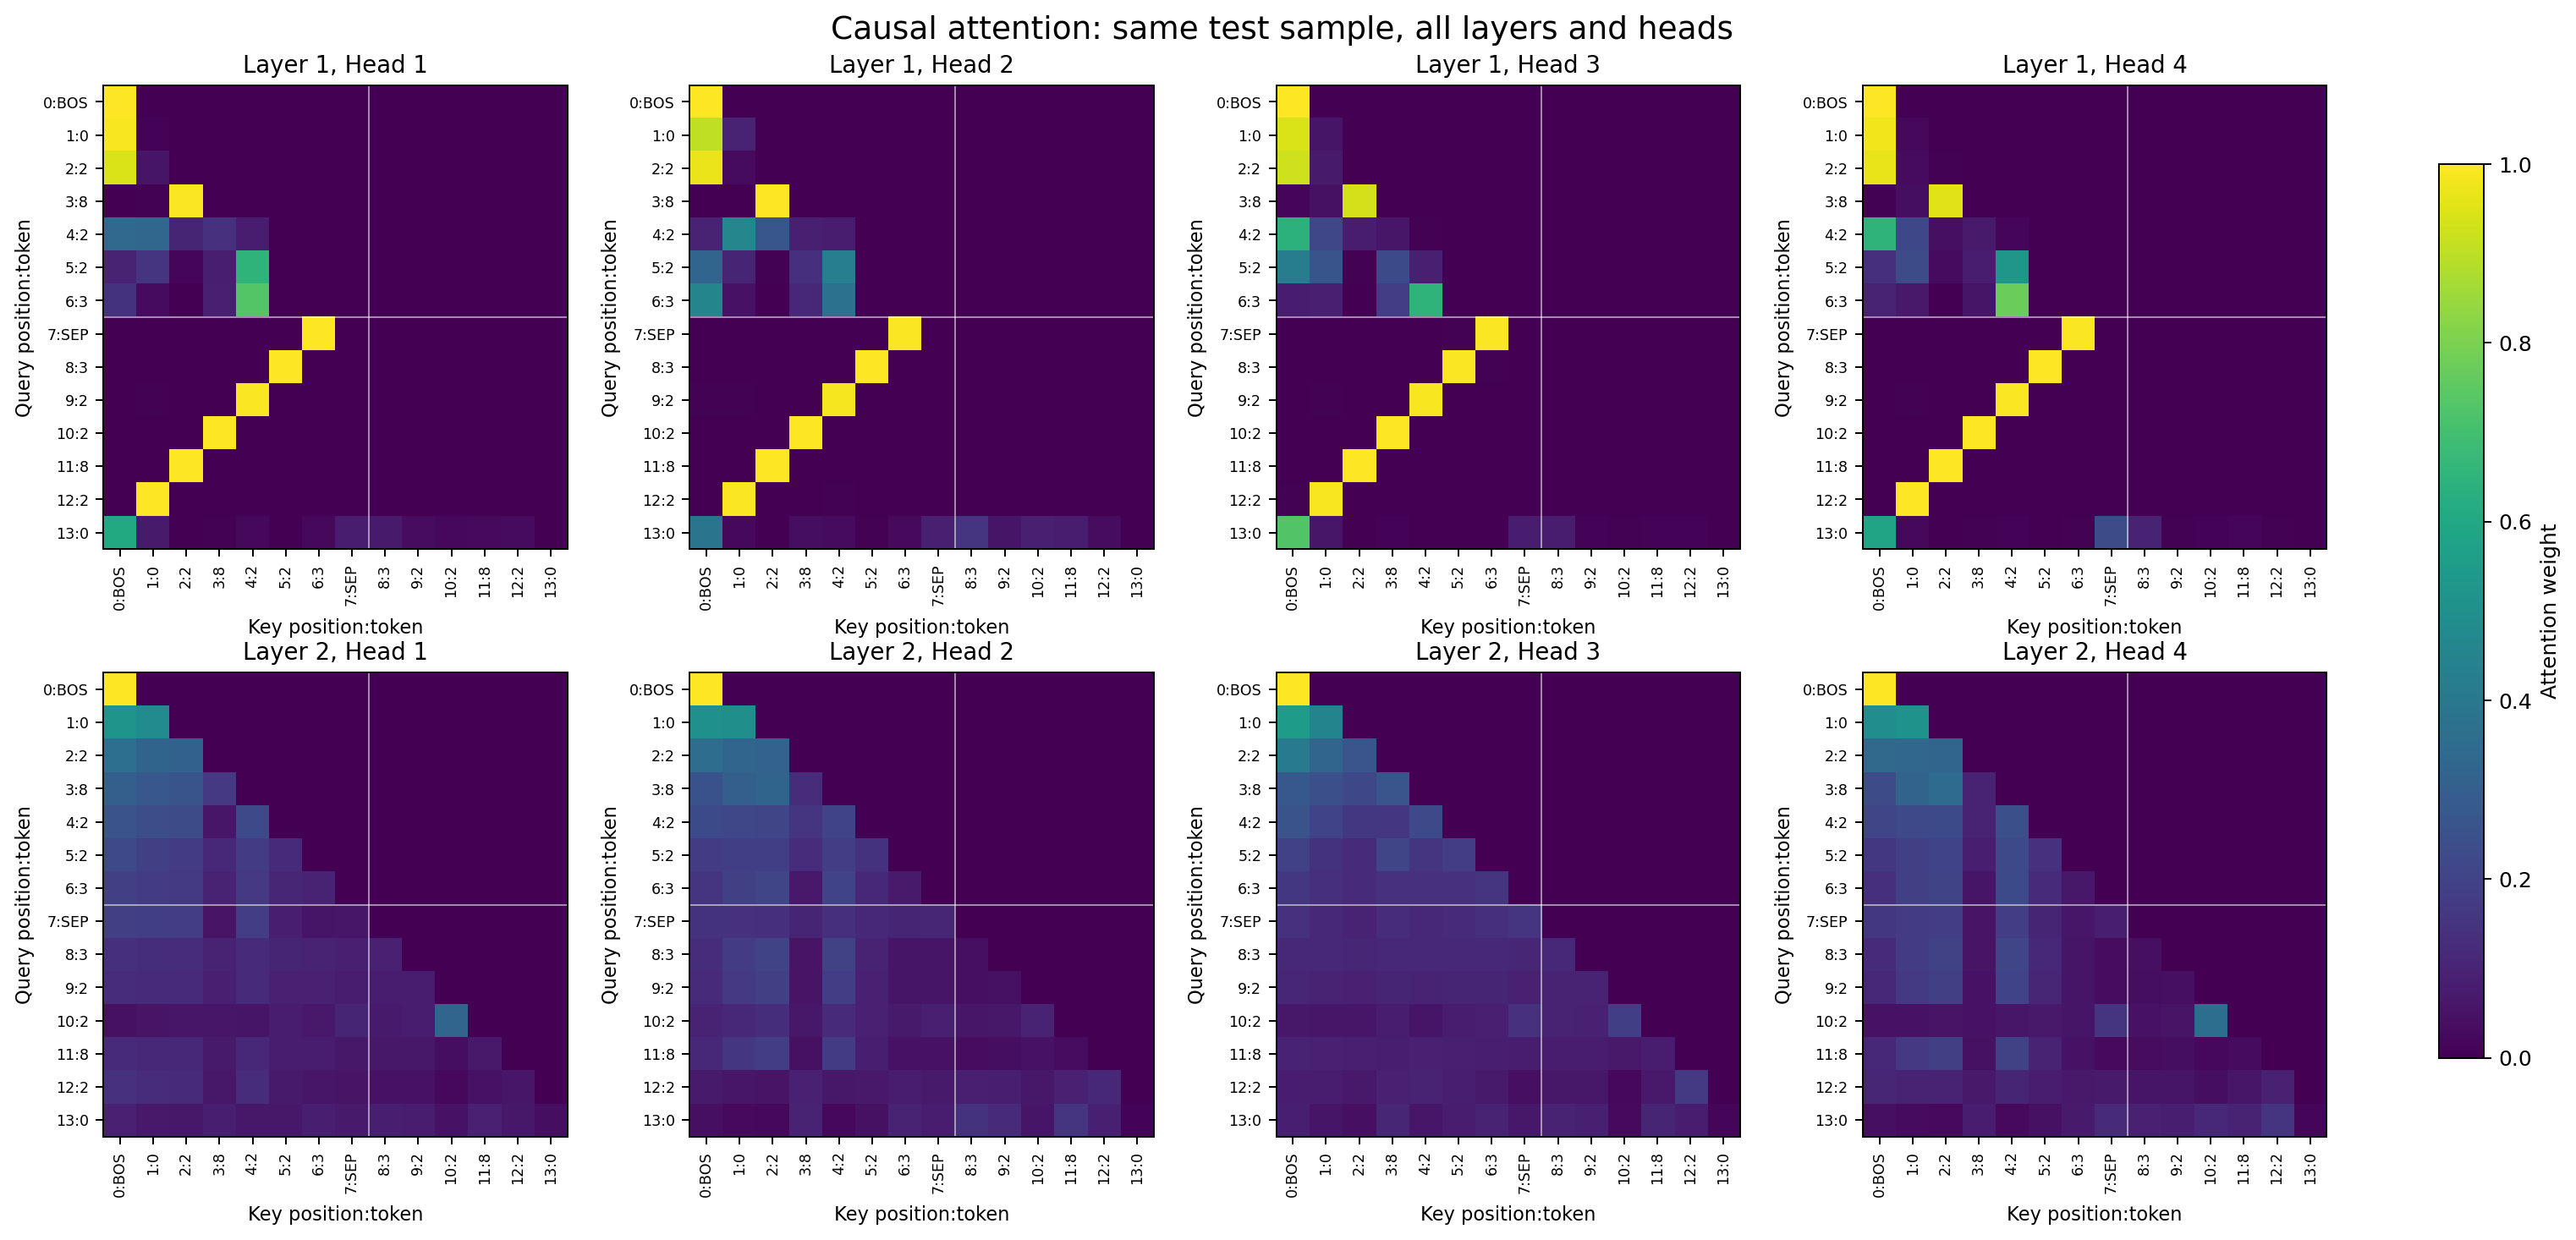

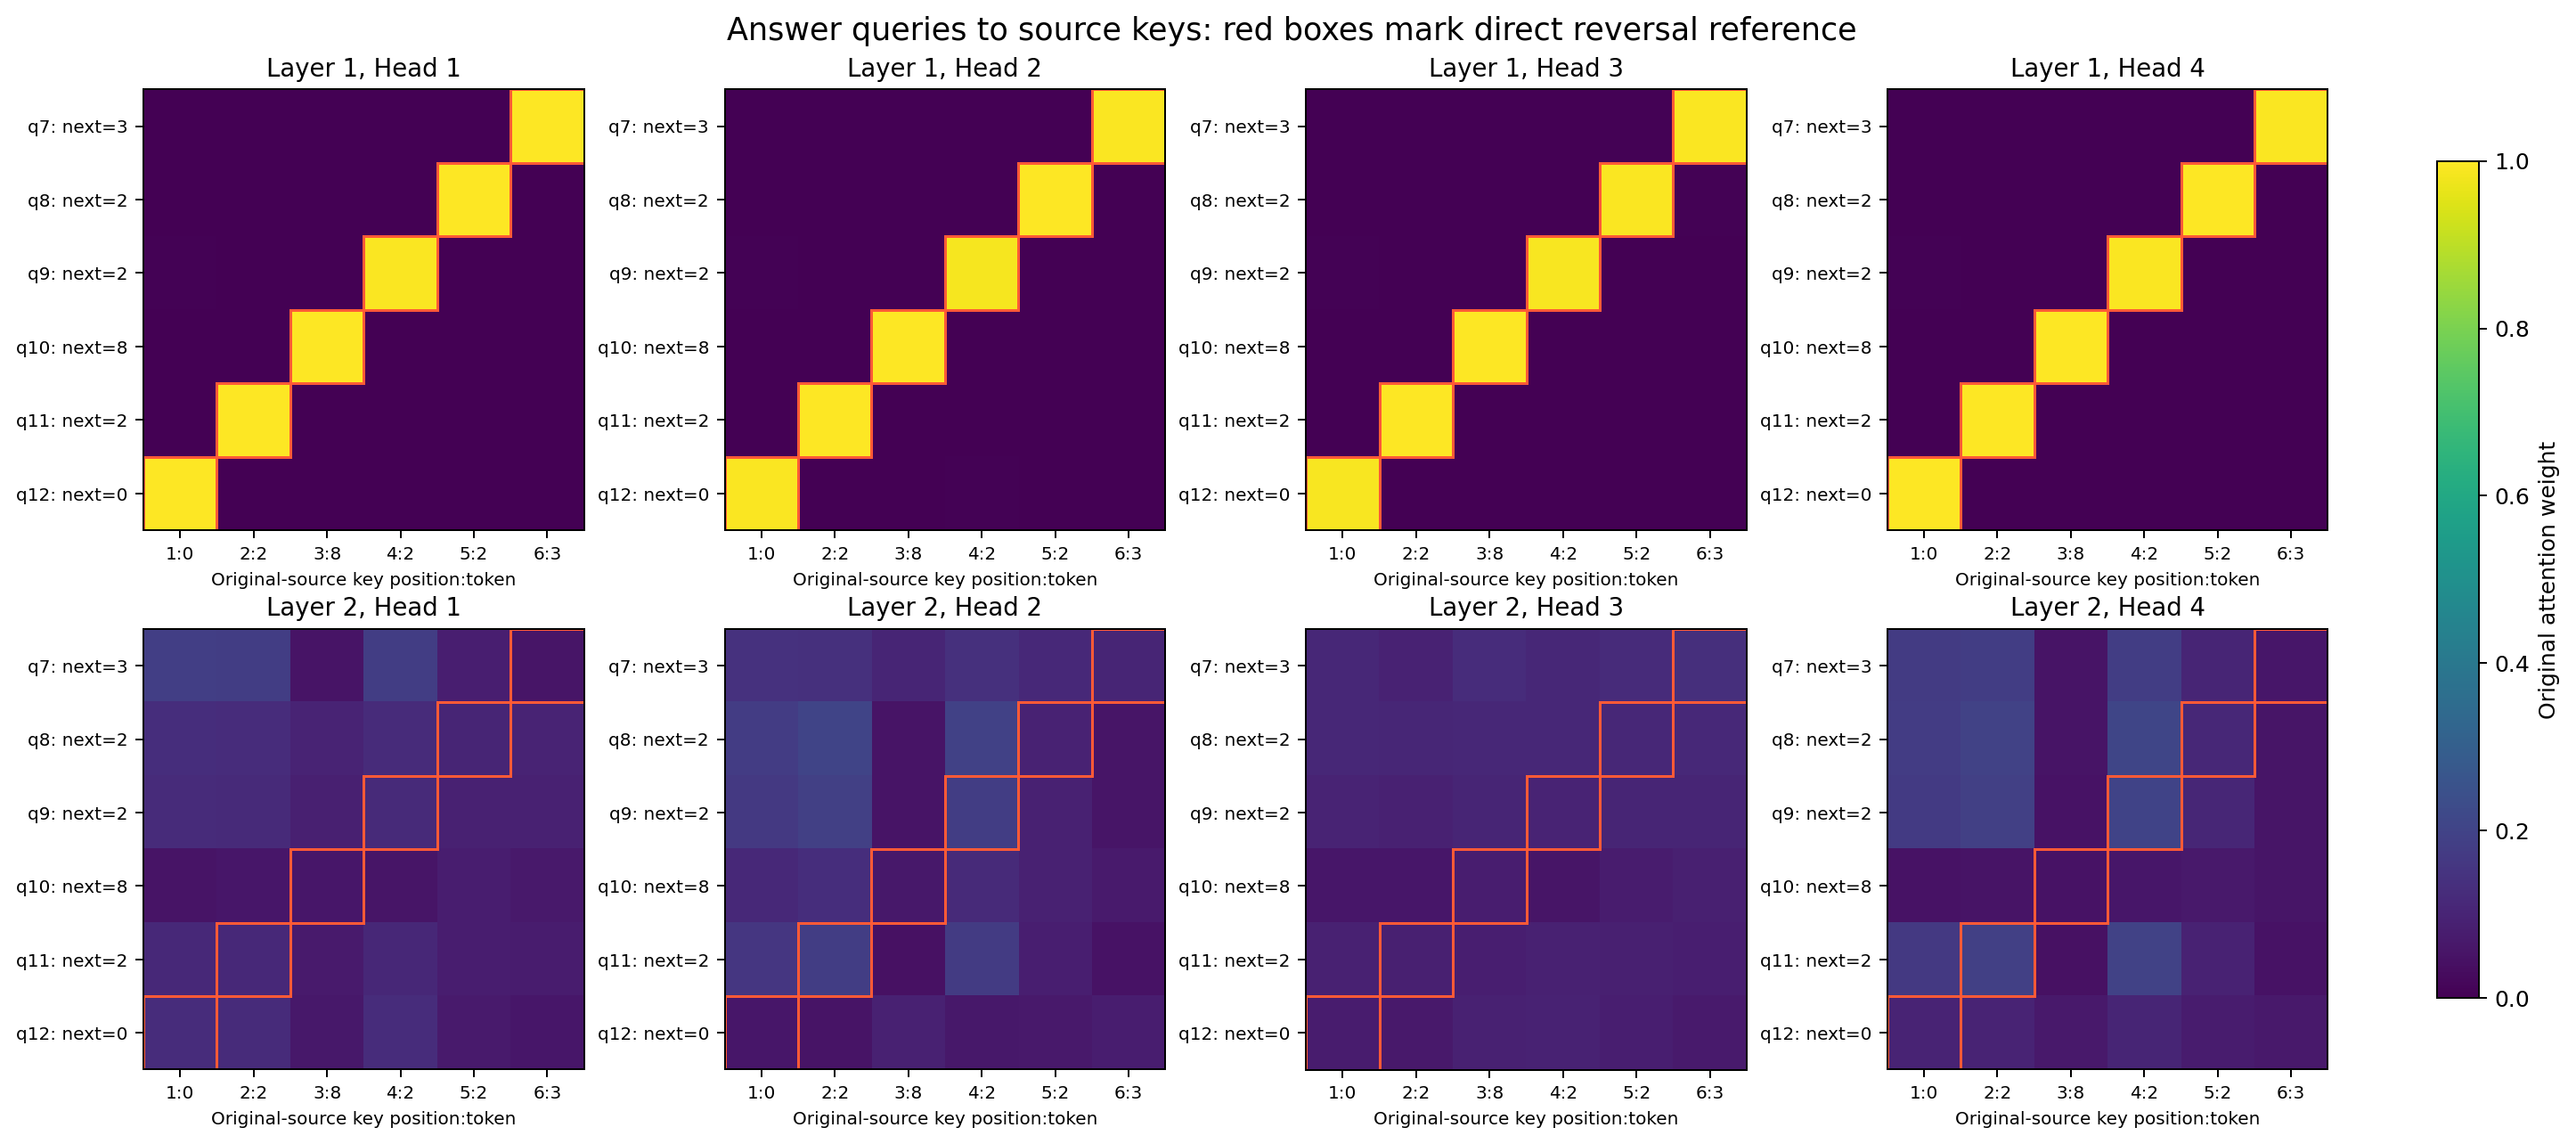

| 层 | 头 | 正确原题位置平均权重 | 答案 query 的未来权重 |
| --- | --- | --- | --- |
| 1 | 1 | 99.81% | 0.00% |
| 1 | 2 | 99.51% | 0.00% |
| 1 | 3 | 99.43% | 0.00% |
| 1 | 4 | 99.79% | 0.00% |
| 2 | 1 | 9.71% | 0.00% |
| 2 | 2 | 11.46% | 0.00% |
| 2 | 3 | 9.78% | 0.00% |
| 2 | 4 | 11.90% | 0.00% |

第一层四头的正确原题位置平均权重为 99.64%，第二层为 10.71%。第一层各头在该样本上都形成清晰的反向位置对齐，头间模式较相近；第二层分布更分散。这只是该样本的权重观察，不能据此断言某个头不可替代或第二层没有作用，因为后层接收的表示已混合前层信息，且模型有残差通路。

## 7. 因果 mask 的机制比较：相同权重

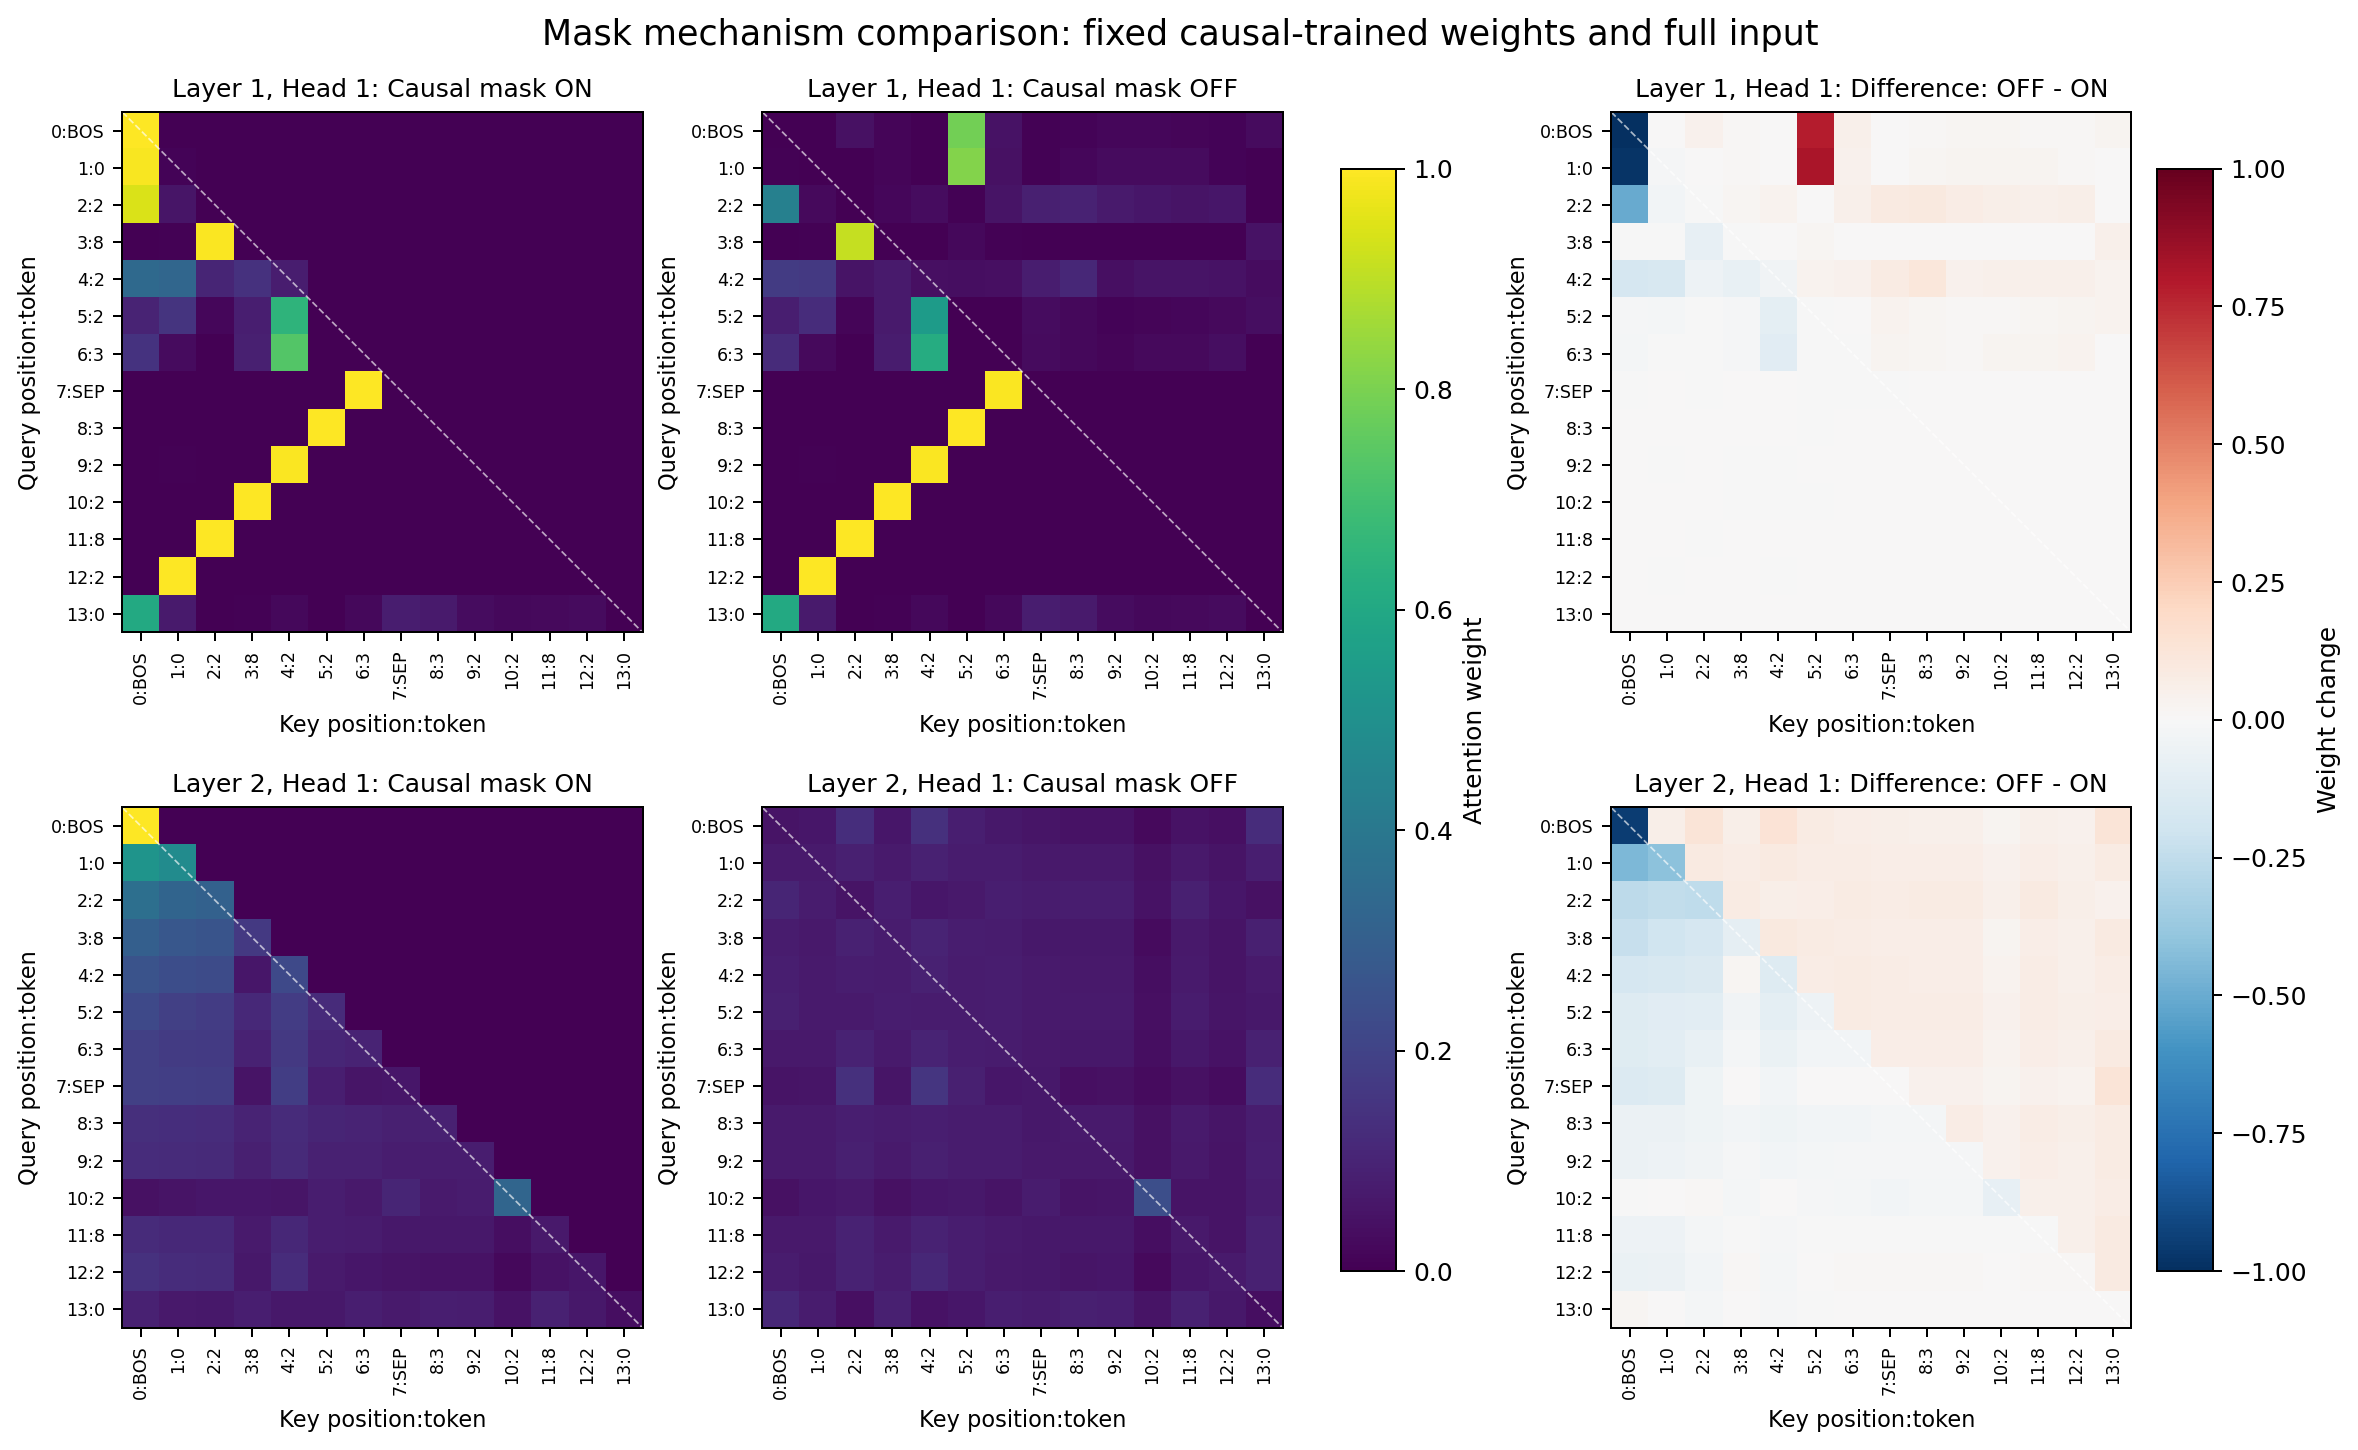

第六步仅切换已经因果训练的完整模型的推理 mask，各层一起切换，参数逐项验证不变。开启时未来位置权重严格为 0；关闭时未来位置可以获得权重。修改未来答案输入后，前缀 logits 最大变化分别为：开启 0.000000，关闭 1.071323。

| 同一权重的推理设置 | 测试教师强制 loss | 数字准确率 | 整序列准确率 |
| --- | --- | --- | --- |
| 开启 mask | 0.00024506 | 100.00% | 100.00% |
| 关闭 mask | 0.00024725 | 100.00% | 100.00% |

当前测试集的独立贪心生成在两种设置下都成功。该实验说明信息可见范围和前缀因果性发生变化，不等同于从头训练无 mask 模型。

## 8. 从头训练消融

单头保留隐藏维度 64，仅将四个 16 维头变为一个 64 维头，投影矩阵大小及参数量保持一致。无 mask 组训练与生成均关闭 mask。两组均重新初始化，使用与完整模型相同的初始数值、数据顺序、训练步数和评估流程。

| 模型 | 头数 | 因果 mask | 参数量 | 步数 | 测试 loss | 数字准确率 | 整序列准确率 | 训练秒 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 完整模型 | 4 | 开启 | 69709 | 600 | 0.00024506 | 100.00% | 100.00% | 11.021 |
| 单头模型 | 1 | 开启 | 69709 | 600 | 0.00025675 | 100.00% | 100.00% | 4.672 |
| 无 mask 模型 | 4 | 关闭 | 69709 | 600 | 0.00023230 | 100.00% | 100.00% | 4.618 |

训练秒数包含验证和检查点保存，是本次单次墙钟测量，不能作为稳定速度排名。

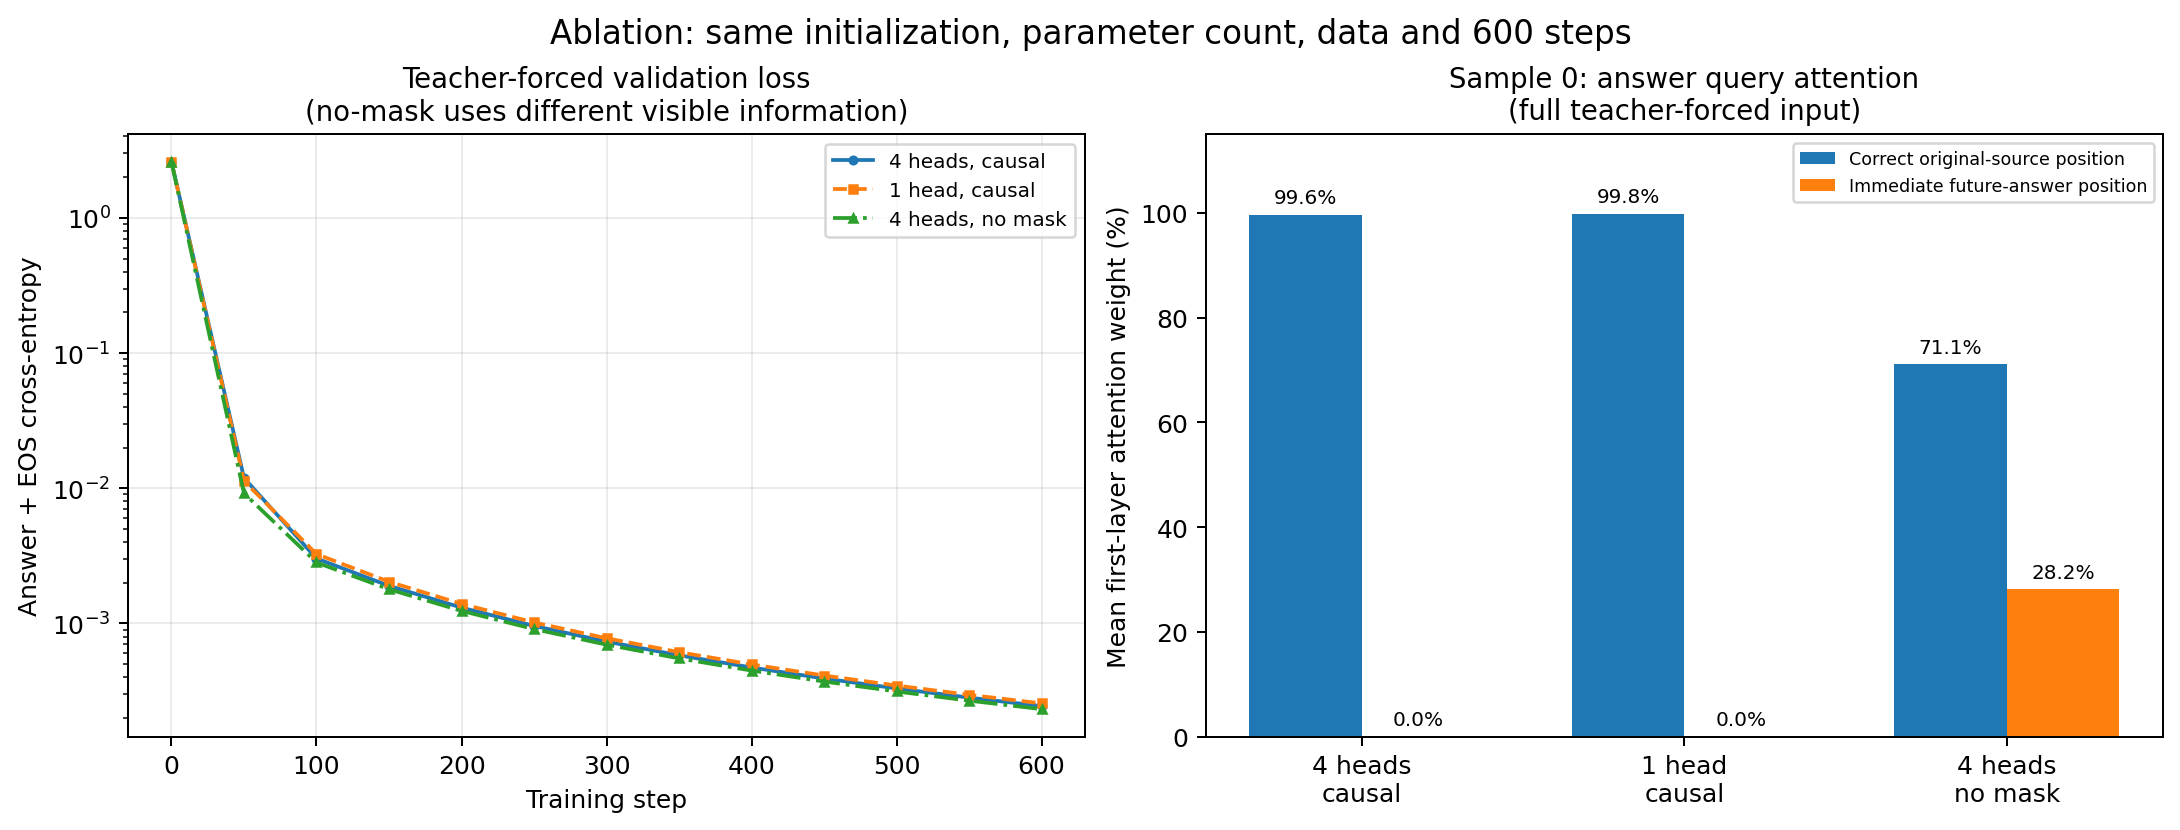

三组均正确生成全部 512 条测试答案，当前固定长度任务出现准确率饱和。本次结果未显示四头相对单头的生成准确率优势，也未观察到无 mask 模型的生成失败。 无 mask 的教师强制输入可读取未来答案，所以其 loss 对应不同的信息条件，较低的数值不能直接解释为更强的自回归生成能力。样本 0 的无 mask 模型第一层，对正确原题位置平均注意力为 71.13%，对紧邻未来答案位置为 28.16%；未来答案信息读取与本次生成仍正确这两个观察需要同时保留。

## 9. 结论与局限

手写注意力和完整模型通过实现检查，模型学会了当前长度 6 的数字反转。完整模型达到预设 90% 整序列准确率期望；该期望由实验方案自行设定，非课件硬性阈值。

本实验仅使用一个随机种子、一种固定长度和一次训练。三组生成准确率的饱和使本次结果无法建立多头或因果 mask 的普遍准确率优势；注意力图主要分析一个样本，也不能代替全局因果解释。未进行变长、跨长度泛化、多种子或额外消融。

## 10. 复现与文件说明

将本 notebook 上传 Colab 免费版，优先选择 GPU，执行“重启会话并运行所有单元”。不需要外部数据、预训练模型或额外安装。CPU 可运行但更慢；原测速逻辑会统一调整预算。报告、图表和指标均由本次运行动态生成。

提交包包含 `.ipynb`、本报告、5 张 PNG 及对应 PDF、消融 CSV/JSON、逐样本预测、训练记录、数据与抽样索引、三组最终权重、环境配置及 SHA256 清单。图片与报告同目录，解压后相对链接可用。重跑验证记录位于 `reproducibility_check.json`；本报告正文在打包前由当前实际结果生成。组员检查无误后自行提交。


In [26]:
# 第 8A 步：从本轮产物生成中文 Markdown 报告，检查图表与预测
from pathlib import Path
import json, csv, hashlib, base64, zipfile, sys
from IPython.display import display, Markdown, HTML
GROUP_NAME = '第24组'
MEMBERS = ['庄隆生', '杨全海', '林艺旻', '谢伯劲']
SUBMISSION_STEM = '实验一_' + GROUP_NAME + '_' + '_'.join(MEMBERS)
OUTPUT_DIR = Path('/content/experiment1_outputs')
def read_json(name):
    return json.loads((OUTPUT_DIR / name).read_text(encoding='utf-8'))
names = ['baseline', 'single_head', 'no_mask']
labels = {'baseline': '完整模型', 'single_head': '单头模型', 'no_mask': '无 mask 模型'}
metrics = {name: read_json(name + '_metrics.json') for name in names}
histories = {name: read_json(name + '_history.json') for name in names}
environment = read_json('environment.json')
config = read_json('training_config.json')
attention_result = read_json('step6_results.json')
diagnostics = read_json('ablation_alignment_diagnostics.json')
all_prediction_rows = {}
csv_checks = []
for name in names:
    with (OUTPUT_DIR / (name + '_predictions.csv')).open(encoding='utf-8-sig', newline='') as handle:
        rows = list(csv.DictReader(handle))
    correct_digits = exact_sequences = 0
    for row in rows:
        expected = row['source'].split()[::-1] + ['<EOS>']
        predicted = row['generated'].split()
        assert row['expected'].split() == expected
        correct_digits += sum(a == b for a, b in zip(predicted[:6], expected[:6]))
        exact_sequences += predicted == expected
        assert (row['exact_match'] == 'True') == (predicted == expected)
    assert len(rows) == metrics[name]['test_samples'] == N_TEST
    assert correct_digits == metrics[name]['correct_digit_tokens']
    assert exact_sequences == metrics[name]['exact_sequences']
    assert metrics[name]['training_steps'] == TRAIN_STEPS
    all_prediction_rows[name] = rows
    csv_checks.append(dict(experiment=name, samples=len(rows), correct_digits=correct_digits,
                           exact_sequences=exact_sequences, independently_verified=True))
assert all([r['source'] for r in all_prediction_rows[name]] ==
           [r['source'] for r in all_prediction_rows['baseline']] for name in names)
figures = ['baseline_loss.png', 'attention_all_heads.png', 'attention_reverse_alignment.png',
           'attention_mask_comparison.png', 'ablation_comparison.png']
for name in figures:
    assert (OUTPUT_DIR / name).is_file() and (OUTPUT_DIR / name).stat().st_size > 1000
    assert (OUTPUT_DIR / name.replace('.png', '.pdf')).is_file()

def md_table(headers, rows):
    return '\n'.join(['| ' + ' | '.join(headers) + ' |',
                     '| ' + ' | '.join(['---'] * len(headers)) + ' |'] +
                    ['| ' + ' | '.join(map(str, row)) + ' |' for row in rows])

result_table = md_table(['模型', '头数', '因果 mask', '参数量', '步数', '测试 loss',
                         '数字准确率', '整序列准确率', '训练秒'], [
    [labels[name], metrics[name]['num_heads'], '开启' if metrics[name]['causal'] else '关闭',
     metrics[name]['parameters'], metrics[name]['training_steps'],
     f"{metrics[name]['test_teacher_forced_loss']:.8f}",
     f"{metrics[name]['token_accuracy']:.2%}", f"{metrics[name]['sequence_accuracy']:.2%}",
     f"{metrics[name]['training_seconds']:.3f}"] for name in names])
loss_table = md_table(['模型', '初始训练 loss', '最终训练 loss', '最终验证 loss'], [
    [labels[name], f"{histories[name][0]['train_loss']:.6f}",
     f"{histories[name][-1]['train_loss']:.8f}", f"{histories[name][-1]['val_loss']:.8f}"]
    for name in names])
sample_table = md_table(['测试编号', '原题', '正确答案', '完整模型生成'], [
    [r['sample_id'], r['source'], r['expected'], r['generated']]
    for r in all_prediction_rows['baseline'][:5]])
stats = [r for r in attention_result['head_statistics'] if r['mode'] == 'causal']
head_table = md_table(['层', '头', '正确原题位置平均权重', '答案 query 的未来权重'], [
    [r['layer'], r['head'], f"{r['expected_source_alignment']:.2%}",
     f"{r['answer_future_mass']:.2%}"] for r in stats])
layer_means = [sum(r['expected_source_alignment'] for r in stats if r['layer'] == layer) / 4
               for layer in (1, 2)]
switch_table = md_table(['同一权重的推理设置', '测试教师强制 loss', '数字准确率', '整序列准确率'], [
    ['开启 mask' if r['inference_causal'] else '关闭 mask', f"{r['teacher_forced_loss']:.8f}",
     f"{r['token_accuracy']:.2%}", f"{r['sequence_accuracy']:.2%}"]
    for r in attention_result['mask_switch']])
perturbation = attention_result['future_perturbation']
no_mask_diag = next(r for r in diagnostics if r['experiment'] == 'no_mask')
baseline = metrics['baseline']
errors = [r for r in all_prediction_rows['baseline'] if r['exact_match'] != 'True']
error_description = (f"完整模型在本次独立测试集中有 {len(errors)} 条错误。" +
    ('以下为首个错误：`' + errors[0]['source'] + '` → `' + errors[0]['generated'] + '`。'
     if errors else '未找到错误样例，报告不虚构错误；完整预测保存在 baseline_predictions.csv。'))
all_perfect = all(metrics[name]['sequence_accuracy'] == 1 for name in names)
conclusion = ('三组均正确生成全部 512 条测试答案，当前固定长度任务出现准确率饱和。'
              '本次结果未显示四头相对单头的生成准确率优势，也未观察到无 mask 模型的生成失败。'
              if all_perfect else '三组的生成差异以结果表为准，不以教师强制 loss 单独判断优劣。')
report = f'''# 实验一：手写注意力机制与 Decoder-only Transformer

组别：{GROUP_NAME}
成员：{'、'.join(MEMBERS)}
平台：Google Colab 免费版；本次设备：{environment['gpu'] or environment['device']}
结果来源：本 notebook 当前从头运行产生的 JSON、CSV、权重和图表。

## 1. 实验目的

手写缩放点积注意力、多头自注意力和因果 mask，理解张量的拆头、拼头与信息可见范围；构建包含位置编码、残差、LayerNorm 和前馈网络的两层 Decoder-only Transformer，学习数字序列反转，并通过注意力图和消融实验分析模型行为。

## 2. 数据与监督方式

固定种子 42，从 0–9 组成的长度 6 序列中无重复抽样，训练 4096 条、验证 256 条、测试 512 条，三者没有交集。保留前导零，词表含数字和 BOS、SEP、EOS 共 13 个 token。

示例：`<BOS> 3 1 4 2 0 5 <SEP> 5 0 2 4 1 3 <EOS>`。
完整序列长 15；训练输入和标签错开一位，均为 `[B,14]`。标签前 7 个位置为 -100，仅计算六个答案数字及 EOS 的交叉熵。输入位置 7 的 SEP 预测第一个答案数字。

训练使用教师强制输入；评估生成只提供 `[BOS]+六个原题数字+[SEP]`，在 eval 和无梯度模式下逐个贪心生成 7 个 token，不输入标准答案，也不限制输出必须为数字。

## 3. 方法与张量形状

令 Q=XW_Q、K=XW_K、V=XW_V，注意力为 `softmax(QK^T/sqrt(d_head)+M)V`。因果 mask 将未来位置分数设为负无穷，对角线保留。softmax 沿 key 维计算，每行权重和为 1。

四头配置中，输入为 `[B,T,64]`，Q/K/V 拆为 `[B,4,T,16]`；注意力矩阵为 `[B,4,T,T]`；加权求和后拼回 `[B,T,64]` 并进行输出投影。单头配置为 `[B,1,T,64]`。Q/K/V、拆头、缩放、mask、softmax、加权、拼头及输出投影均手写；PyTorch 官方 MultiheadAttention 仅用于独立数值验证。

模型使用 token embedding 与可学习位置编码，2 个 Pre-LayerNorm block，每个 block 为“LN→注意力→残差”和“LN→线性64→128→GELU→线性128→64→残差”，末尾 LN 和 13 类输出层。dropout 为 0。

## 4. 配置与验证

三组隐藏维度 64、前馈维度 128、层数 2、参数量 {baseline['parameters']}；Adam 学习率 0.003，batch size 64，梯度裁剪 1，统一训练 {TRAIN_STEPS} 步，采用最后一步模型。测速模型丢弃，正式训练从种子 42 初始化；数据抽样种子 142、逐步样本索引完全共用。每次记录 loss 都在 eval 模式下计算完整训练集与验证集的目标区间平均交叉熵。

本次环境：Python {environment['python'].split()[0]}，PyTorch {environment['pytorch']}，NumPy {environment['numpy']}，Matplotlib {environment['matplotlib']}。无需额外安装或付费服务。

检查覆盖数据唯一性、错位标签、每条 7 个监督目标、注意力形状、逐行归一化、未来权重为零、改变未来 token 后因果前缀不变、官方数值对照、有限梯度与一次参数更新。消融控制还校验初始权重、数据和抽样顺序的哈希；保存后的三组权重重新加载并核对前 32 条生成。预测 CSV 的 512 条记录再次独立按原题反转重算指标。

## 5. Loss 与真实生成

{loss_table}

![完整模型训练和验证 loss](baseline_loss.png)

完整模型测试数字准确率为 {baseline['token_accuracy']:.2%}（{baseline['correct_digit_tokens']}/3072），整序列准确率为 {baseline['sequence_accuracy']:.2%}（{baseline['exact_sequences']}/512）。整序列要求六个数字全对且第 7 个输出正确为 EOS；提前结束或输出特殊符号造成的数字缺失算错。教师强制测试 loss 为 {baseline['test_teacher_forced_loss']:.8f}。

{sample_table}

{error_description}

## 6. 不同层、不同头的注意力

展示固定测试样本 0，题目为 `{' '.join(map(str, attention_result['sample']['source']))}`。热图纵轴是 query，横轴是 key，标签同时给出位置与 token，颜色表示原始注意力权重，使用统一范围 0–1。query 位置 i 的表示预测 token i+1，因此六个答案的 query 为 7–12，其正确原题 key 位置依次为 6、5、4、3、2、1；相同数字也按位置区分。局部反转图不重新归一化。

![2 层 4 头注意力](attention_all_heads.png)

![答案 query 与原题 key 的反向位置对齐](attention_reverse_alignment.png)

{head_table}

第一层四头的正确原题位置平均权重为 {layer_means[0]:.2%}，第二层为 {layer_means[1]:.2%}。第一层各头在该样本上都形成清晰的反向位置对齐，头间模式较相近；第二层分布更分散。这只是该样本的权重观察，不能据此断言某个头不可替代或第二层没有作用，因为后层接收的表示已混合前层信息，且模型有残差通路。

## 7. 因果 mask 的机制比较：相同权重

![同一因果训练权重下开启与关闭 mask](attention_mask_comparison.png)

第六步仅切换已经因果训练的完整模型的推理 mask，各层一起切换，参数逐项验证不变。开启时未来位置权重严格为 0；关闭时未来位置可以获得权重。修改未来答案输入后，前缀 logits 最大变化分别为：开启 {perturbation['causal_prefix_change']:.6f}，关闭 {perturbation['unmasked_prefix_change']:.6f}。

{switch_table}

当前测试集的独立贪心生成在两种设置下都成功。该实验说明信息可见范围和前缀因果性发生变化，不等同于从头训练无 mask 模型。

## 8. 从头训练消融

单头保留隐藏维度 64，仅将四个 16 维头变为一个 64 维头，投影矩阵大小及参数量保持一致。无 mask 组训练与生成均关闭 mask。两组均重新初始化，使用与完整模型相同的初始数值、数据顺序、训练步数和评估流程。

{result_table}

训练秒数包含验证和检查点保存，是本次单次墙钟测量，不能作为稳定速度排名。

![消融收敛与注意力比较](ablation_comparison.png)

{conclusion} 无 mask 的教师强制输入可读取未来答案，所以其 loss 对应不同的信息条件，较低的数值不能直接解释为更强的自回归生成能力。样本 0 的无 mask 模型第一层，对正确原题位置平均注意力为 {no_mask_diag['first_layer_source_alignment']:.2%}，对紧邻未来答案位置为 {no_mask_diag['first_layer_next_answer_weight']:.2%}；未来答案信息读取与本次生成仍正确这两个观察需要同时保留。

## 9. 结论与局限

手写注意力和完整模型通过实现检查，模型学会了当前长度 6 的数字反转。完整模型达到预设 90% 整序列准确率期望；该期望由实验方案自行设定，非课件硬性阈值。

本实验仅使用一个随机种子、一种固定长度和一次训练。三组生成准确率的饱和使本次结果无法建立多头或因果 mask 的普遍准确率优势；注意力图主要分析一个样本，也不能代替全局因果解释。未进行变长、跨长度泛化、多种子或额外消融。

## 10. 复现与文件说明

将本 notebook 上传 Colab 免费版，优先选择 GPU，执行“重启会话并运行所有单元”。不需要外部数据、预训练模型或额外安装。CPU 可运行但更慢；原测速逻辑会统一调整预算。报告、图表和指标均由本次运行动态生成。

提交包包含 `.ipynb`、本报告、5 张 PNG 及对应 PDF、消融 CSV/JSON、逐样本预测、训练记录、数据与抽样索引、三组最终权重、环境配置及 SHA256 清单。图片与报告同目录，解压后相对链接可用。重跑验证记录位于 `reproducibility_check.json`；本报告正文在打包前由当前实际结果生成。组员检查无误后自行提交。
'''
REPORT_PATH = OUTPUT_DIR / (SUBMISSION_STEM + '_报告.md')
REPORT_PATH.write_text(report, encoding='utf-8')
(OUTPUT_DIR / 'prediction_csv_checks.json').write_text(json.dumps(csv_checks, ensure_ascii=False, indent=2), encoding='utf-8')
print('PASS: report values read from current artifacts; all 3 prediction CSV files independently verified.')
print('PASS: all 5 PNG/PDF figure pairs present.')
print('Report:', REPORT_PATH.name, '|', len(report), 'characters')
report_preview = report
for filename in figures:
    inline_image = base64.b64encode((OUTPUT_DIR / filename).read_bytes()).decode('ascii')
    report_preview = report_preview.replace('](' + filename + ')',
        '](data:image/png;base64,' + inline_image + ')')
display(Markdown(report_preview))


In [27]:
# 第 8B 步：验证重启后全部运行，导出 notebook、报告、图表、结果和权重
from google.colab import _message
from datetime import datetime, timezone
import copy
import nbformat
print('Checking clean sequential execution and final deliverables...', flush=True)
snapshot_response = _message.blocking_request('get_ipynb', timeout_sec=180)
if not snapshot_response or 'ipynb' not in snapshot_response:
    raise RuntimeError('Colab notebook export did not respond; save the notebook and rerun this export cell.')
snapshot = snapshot_response['ipynb']
final_notebook = copy.deepcopy(snapshot)
code_cells = [cell for cell in final_notebook['cells'] if cell['cell_type'] == 'code']
previous_counts = [cell.get('execution_count') for cell in code_cells[:-1]]
assert previous_counts == list(range(1, len(code_cells))), previous_counts
assert all(output.get('output_type') != 'error' for cell in code_cells
           for output in cell.get('outputs', [])), 'Notebook contains an error output'
assert code_cells[-1]['source'][0].startswith('# 第 8B') if isinstance(code_cells[-1]['source'], list) else code_cells[-1]['source'].startswith('# 第 8B')
assert all(read_json(name + '_metrics.json')['training_steps'] == TRAIN_STEPS for name in names)
assert all(r['weights_match'] and r['first_32_generations_match']
           for r in read_json('ablation_reload_checks.json'))
assert len(csv_checks) == 3 and all(r['independently_verified'] for r in csv_checks)
repro_check = dict(
    clean_sequential_execution=True, session_started_utc=RUN_STARTED_UTC,
    completed_utc=datetime.now(timezone.utc).isoformat(), process_id=RUN_PROCESS_ID,
    previous_code_cell_execution_counts=previous_counts,
    code_cells=len(code_cells), all_previous_code_cells_completed=True,
    notebook_error_outputs=0, device=str(device), gpu=environment['gpu'],
    shared_training_steps=TRAIN_STEPS, prediction_csv_checks=csv_checks,
    saved_weights_reload=read_json('ablation_reload_checks.json'),
    note='Checked after restarting the Colab session and running all cells in order. Final export cell records this check before transfer.')
(OUTPUT_DIR / 'reproducibility_check.json').write_text(
    json.dumps(repro_check, ensure_ascii=False, indent=2), encoding='utf-8')

# 只移除体积很大的传输链接；训练日志、报告和图表输出均保留。
for cell in final_notebook['cells']:
    if cell['cell_type'] != 'code':
        continue
    clean_outputs = []
    for output in cell.get('outputs', []):
        html_value = output.get('data', {}).get('text/html', '')
        if isinstance(html_value, list):
            html_value = ''.join(html_value)
        if 'data:application/zip;base64,' not in html_value:
            clean_outputs.append(output)
    cell['outputs'] = clean_outputs
final_notebook['metadata'].pop('widgets', None)
final_notebook['metadata']['title'] = SUBMISSION_STEM + '.ipynb'
final_notebook['metadata']['experiment1_reproducibility'] = dict(
    clean_sequential_execution=True, shared_training_steps=TRAIN_STEPS,
    session_started_utc=RUN_STARTED_UTC)
code_cells[-1]['execution_count'] = code_cells[-1].get('execution_count') or len(code_cells)
code_cells[-1]['outputs'] = [dict(output_type='stream', name='stdout', text=[
    f'PASS: fresh sequential run; {len(code_cells)} code cells; no error outputs.\n',
    'PASS: all three prediction CSVs, model reload checks, and five figure pairs verified.\n',
    'Final export includes this notebook, report, plots, data, results and weights.\n'])]
nb_object = nbformat.from_dict(final_notebook)
nbformat.validate(nb_object)
NOTEBOOK_PATH = OUTPUT_DIR / (SUBMISSION_STEM + '.ipynb')
NOTEBOOK_PATH.write_text(nbformat.writes(nb_object), encoding='utf-8')
readme = f'''# 实验一最终提交文件

第24组：庄隆生、杨全海、林艺旻、谢伯劲。

1. 先阅读 `{REPORT_PATH.name}`。图表与报告同目录，解压后查看。
2. 将 `{NOTEBOOK_PATH.name}` 上传 Google Colab，选择免费 GPU，执行“重启会话并运行所有单元”。默认不安装软件，不依赖外部文件。
3. CPU 采用相同数据和流程，统一使用测速确定的较小训练预算；结果可能与本包的 T4/600 步结果不同。
4. 全部表格、报告和图表都会按当前运行重新生成；末尾给出最终包下载链接。
5. `reproducibility_check.json` 是本次重启、全部运行和预测复核记录；`SHA256.json` 可核对每个文件。
6. 本包保留全部关键代码和输出，仅去掉中间传输 ZIP 的嵌套下载链接。三组 final.pt 为最终权重，训练时 latest.pt 不纳入提交包。

请组员核对姓名、报告和实际输出后自行提交。
'''
(OUTPUT_DIR / 'README.md').write_text(readme, encoding='utf-8')
package_files = [path for path in sorted(OUTPUT_DIR.iterdir())
                 if path.is_file() and path.name != 'SHA256.json' and not path.name.endswith('_latest.pt')]
assert NOTEBOOK_PATH in package_files and REPORT_PATH in package_files
manifest = {path.name: hashlib.sha256(path.read_bytes()).hexdigest() for path in package_files}
(OUTPUT_DIR / 'SHA256.json').write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8')
FINAL_ZIP = Path('/content') / (SUBMISSION_STEM + '_最终提交.zip')
with zipfile.ZipFile(FINAL_ZIP, 'w', zipfile.ZIP_DEFLATED) as archive:
    for path in package_files + [OUTPUT_DIR / 'SHA256.json']:
        archive.write(path, SUBMISSION_STEM + '/' + path.name)
with zipfile.ZipFile(FINAL_ZIP) as archive:
    assert archive.testzip() is None
    for name, digest in manifest.items():
        assert hashlib.sha256(archive.read(SUBMISSION_STEM + '/' + name)).hexdigest() == digest
print(f'PASS: fresh sequential run of {len(code_cells)} code cells; no notebook errors.')
print(f'PASS: {len(package_files)} files plus SHA256 manifest; all archived bytes verified.')
print(f'Final ZIP: {FINAL_ZIP.name} ({FINAL_ZIP.stat().st_size / 1024:.1f} KiB)')
display(Markdown('### 最终提交包已生成\n\n包含 notebook、中文报告、5 组图表、消融表、完整预测、训练记录、数据和三组模型权重。'))
final_payload = base64.b64encode(FINAL_ZIP.read_bytes()).decode('ascii')
display(HTML(f'<a download="{FINAL_ZIP.name}" href="data:application/zip;base64,{final_payload}">下载第24组最终提交 ZIP</a>'))


PASS: fresh sequential run; 27 code cells; no error outputs.
PASS: all three prediction CSVs, model reload checks, and five figure pairs verified.
Final export includes this notebook, report, plots, data, results and weights.
